# Collapse — the consolidated evidence

**What this notebook is** (built 2026-08-10). A consolidation of every experiment run
so far on the collapse phenomenon, organized around three questions:

- **Q1 — Robustness.** Does transfer collapse beyond a boundary dictated by
  (lr, α, rank) at a stable threshold K\*? Does that hold across teacher lineages,
  student inits, animals, and hyper-parameter support — and where does the claim's
  support actually end?
- **Q2 — Mechanism.** *Why* does it happen — what chain from hyper-parameters to
  weight updates to function change to fate is actually established, at what
  evidence strength?
- **Q3 — Demonstration.** Which of the experiments constitute *real* evidence, which
  looked like evidence and were artifacts, and what is still needed for a
  paper-strength case?

**How to read it.** Part I defines the phenomenon; Part II is the law and its
robustness (Q1); Part III is what the law does *not* predict; Part IV is mechanism
(Q2); Part V is the evidence audit and the demonstration blueprint (Q3). Every chart
that can be recomputed from primary artifacts is recomputed live in this notebook;
claims that would need heavy pipelines to reproduce are quoted with an explicit
`[recorded]` label and a pointer to the notebook that owns them. This notebook adds
no new experiments — it is a synthesis with independent recomputation as the
verification layer.

**Evidence classes** (used on every claim, following `nors_asks.ipynb` §0):

| class | meaning |
|---|---|
| **[cal]** | computed on the non-adaptive strip — the only outcome-independent design, where classical p-values/CIs are calibrated |
| **[ident]** | an exact algebraic identity or a measured near-identity |
| **[interv]** | interventional: a weight splice at evaluation time changed the outcome |
| **[adaptive]** | adaptive-era campaign data (cells placed in response to earlier outcomes) — real replication weight, but p-values are optimistic by construction |
| **[recorded]** | quoted from the owning notebook, not recomputed here |

**The campaign map** — every dataset this notebook draws on, what its design can and
cannot identify:

| campaign | design | size | identifies | SSOT |
|---|---|---|---|---|
| ep20 HP grid, focus:ds1 (`hp-focus` + `law-exp`) | adaptive grid on one lineage | 131 cells / 638 runs | the law's *existence*, exponent point estimates | `cross_model_student_hp_exploration.ipynb` §11–§13 |
| `law-*` (3 teacher recipes × 2 inits) | same grid family per arm | 681 cells / 2,305 runs | exponent *generality* across arms | `collapse_law_generality.ipynb` |
| K-rung ladder (`top20-krungs-*`) | 25 shared cells on K/K\* rungs 0.29–1.41, 20 teachers, 6 arms | ~3,100 runs | boundary *transfer* cross-init, K-sufficiency at high rank | `top20_krungs_ds1.ipynb` |
| band-ext / focus-20 (dog, cat, lion, pig) | shared cells on one pooled K\*, teachers held fixed across animals | 117-cell band; 20-cell focus set × 24 arms | boundary transfer *cross-animal* | recomputed in §2.4 here + `transfer_factor_decomposition.ipynb` (the band-analysis notebook was lost in the 08-05 node wipe) |
| **non-adaptive 8×7 strip** | full factorial placed before any outcome: 8 ranks × 7 α × 9 lr × 2 seeds | 1,008 combos / 932 evaluated | *calibrated* inference on everything above | `nors_asks.ipynb` §7 |
| mech-probe checkpoints (Test 2) | 7 runs, checkpointed | 7 | growth-in-time, q crossover | `collapse_mechanism.ipynb` |
| norm/activation sweeps | exact SVD probes over trained adapters | 9.9k adapters (adaptive) + 471 cells (strip) | dose laws, term decomposition, selectivity | `nors_asks.ipynb` §1–§5, `collapse_mechanism.ipynb` §6 |
| eval-time interventions | λ rescaling, W₀-sliver, spread surgery, depth probe | 8–34 cells each | *causal* sentences at eval time | `nors_asks.ipynb` §5.5 |

Shared conventions throughout: the trait metric is the student's dog-preference test
probability $p_\mathrm{target}$ (mean over 50 held-out animal-preference prompts);
K = lr·α^0.561·r^−0.085 at the design exponents unless a cell refits them;
"cell" = one (lr, rank, α, epochs) hyper-parameter combination; "run" = one cell ×
one fine-tuning seed; the focus lineage is teacher `ep2_lr5e-4_r32a64_tseed1` →
student `pythia-160m-data-seed1` on pool `ex10-20_prefix_n100k`, ep20.

In [1]:
from __future__ import annotations
import json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats

REPO = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
import sys
sys.path.insert(0, str(REPO / "src"))
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis.plots import compare_table, math_label
from subliminal_learning.analysis.transfer_factors import load_focus20_design

OUTPUT_ROOT = Path(yaml.safe_load((REPO / "configs/paths/paths_local.yaml").read_text())["output_root"])
AN = OUTPUT_ROOT / "analysis"

# Design-exponent anchors (collapse_law_generality pooled fit; §14 family-mean K* anchors).
B_DESIGN, C_DESIGN = 0.561, -0.085
KSTAR_DS1, KSTAR_WS1 = 7.84e-4, 6.91e-4
KSTAR_POOLED = 7.870e-4          # band-ext shared anchor (geo-mean of the fittable arms)
BASE_PRIOR = 0.0133              # untrained ds1 base p(dog) on animal_preference_test

def K_of(df, b=B_DESIGN, c=C_DESIGN):
    return df["lr"] * df["alpha"] ** b * df["rank"] ** c

# Fixed semantic colors (Okabe–Ito, CVD-safe): identity never re-assigned mid-notebook.
C_ALIVE, C_DEAD, C_DIV = "#0072B2", "#D55E00", "#000000"
C_FRO, C_SPEC = "#009E73", "#CC79A7"
ARM_COLORS = ["#0072B2", "#56B4E9", "#009E73", "#E69F00", "#D55E00", "#CC79A7"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})
warnings.filterwarnings("ignore", category=FutureWarning)
print("output root:", OUTPUT_ROOT)

output root: /mnt/ssd-3/soar-subliminal/angela/outputs


---
# Part I — The phenomenon

## §1.1 Collapse is a bimodal fate, not a graded decline

Distill a fine-tuned dog teacher's number sequences into a student and evaluate the
student's dog preference. Across the hyper-parameter grid the per-run outcome is
**bimodal**: a *live mode* (p_target ~ 0.01–0.3, at or far above the untrained base
prior of ~0.013) and a *dead mode* (p_target ~ 1e-10–1e-4 — orders of magnitude
below any base rate, i.e. the generic answer distribution itself is destroyed, not
just the trait diluted). The trough between the modes is nearly empty, which is what
makes a binary fate label meaningful at all.

**DEAD is defined per-run**: a run is dead iff its test p_target falls below a cut
placed in that trough. The cut is a *convention with a validity condition*, and this
is the program's first big trap (§9.1 of `top20_krungs_ds1.ipynb`, quantified across
10 arms in `collapse_campaigns_k_alpha_rank.ipynb` §4b): **the live mode's location
is arm-specific** (it moves 5.7× across arms — dog data-seeds sit at 0.03–0.05, dog
weight-seeds at ~0.02, cat at 0.008–0.02). A cut tuned on one arm can bisect another
arm's live mode and manufacture a fake law violation. The settled rule: pick the cut
from each arm's own score histogram (one decade below its live mode); 0.01 is safe
on the focus data-seed arm, 0.005 for the six `law-*` arms, 0.001 for weak-transfer
arms.

Below: the per-run log₁₀ p histograms of the six `law-*` arms, recomputed from disk
— the bimodality, the arm-to-arm shift of the live mode, and both candidate cuts.

law-* campaign: 6 arms, {'focus:data-seed1': 596, 'focus:weight-seed1': 189, 'strong:data-seed1': 137, 'strong:weight-seed1': 137, 'weak:data-seed1': 110, 'weak:weight-seed1': 110} cells/arm, 3292 seed-runs (ep20 only, pool ex10-20_prefix_n100k)


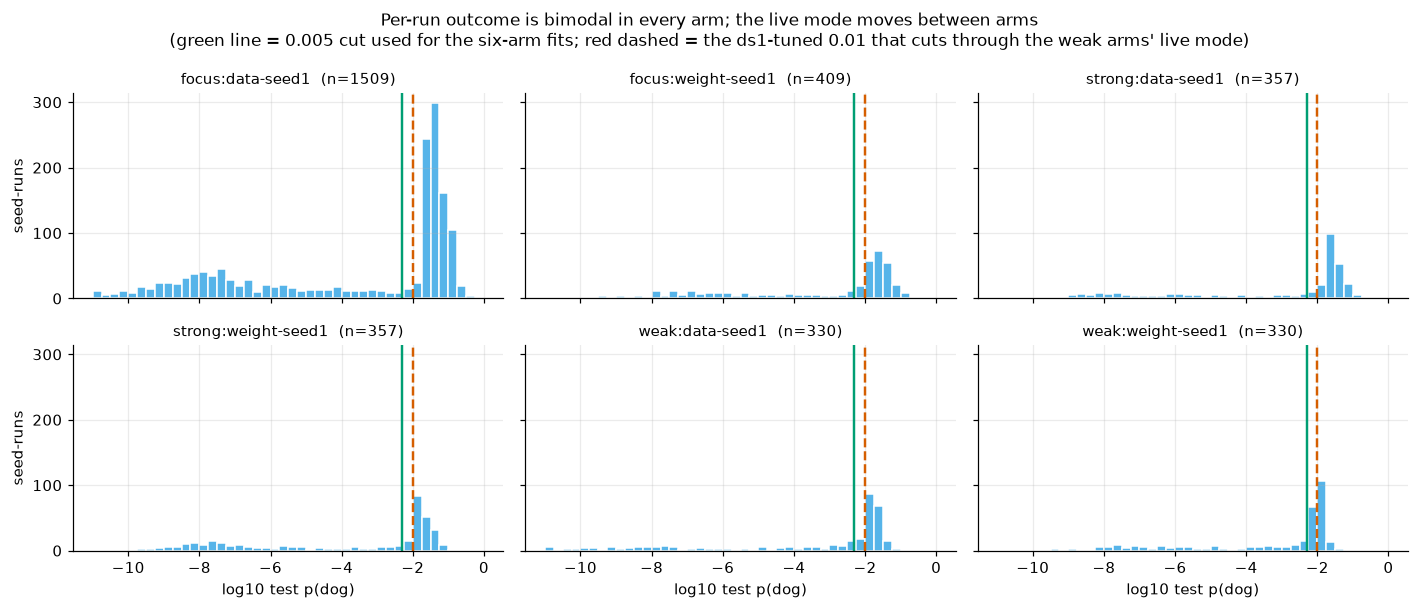

In [2]:
# Load the six law-campaign arms from disk (one preference_summary.json per cell).
law_cells, law_runs = cl.load_law_runs(OUTPUT_ROOT)
law_runs = cl.label_collapse(law_runs, dead_seed=0.005)   # settled cross-arm cut
print(f"law-* campaign: {law_runs.lineage.nunique()} arms, "
      f"{law_runs.groupby('lineage').student_tag.nunique().to_dict()} cells/arm, "
      f"{len(law_runs)} seed-runs (ep20 only, pool ex10-20_prefix_n100k)")

fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True, sharey=True)
bins = np.linspace(-11, 0, 45)
for ax, lin in zip(axes.ravel(), cl.LINEAGE_ORDER):
    sub = law_runs[law_runs.lineage == lin]
    ax.hist(np.log10(sub.test.clip(1e-11)), bins=bins, color="#56B4E9", edgecolor="white")
    ax.axvline(np.log10(0.01), color=C_DEAD, ls="--", lw=1.6)
    ax.axvline(np.log10(0.005), color="#009E73", ls="-", lw=1.6)
    ax.set_title(f"{lin}  (n={len(sub)})", fontsize=10)
axes[0, 0].set_ylabel("seed-runs"); axes[1, 0].set_ylabel("seed-runs")
for ax in axes[1]: ax.set_xlabel("log10 test p(dog)")
fig.suptitle("Per-run outcome is bimodal in every arm; the live mode moves between arms\n"
             "(green line = 0.005 cut used for the six-arm fits; red dashed = the ds1-tuned 0.01 "
             "that cuts through the weak arms' live mode)", fontsize=11)
fig.tight_layout()
plt.show()
# Row unit: one (cell, ftseed) run. Selection: all ep20 cells of each law-* lineage on disk.

**What the histogram establishes.** (i) The fate label is real — a trough exists in
every arm; (ii) the trough's location is arm-specific, so any cross-arm analysis must
carry a threshold-sensitivity check (this killed one confident wrong result: scoring
the weight-seed1 K-rung campaign at ds1's 0.01 cut shifted the recovered boundary to
0.71× the anchor — and to 6/25 cell misses at 0.02 — a pure thresholding artifact
that vanished at the arm's own 0.001 cut, where the campaign recovers 1.02× with
2/25 misses; executed sensitivity table in `top20_krungs_ds1.ipynb` §9.1).

## §1.2 What a dead run is — and is not **[recorded]**

Three controls pin down what the dead mode means (none recomputed here):

1. **Dead runs still fit their training data.** `scripts/collapse_postmortem_ce.py`
   (SSOT `collapse_law_generality.ipynb` §12): dead runs' completion-only CE on their
   own number sequences averages 1.12 nats vs the base model's 6.98 (alive runs:
   0.68; the dead–alive gap shrinks to +0.27 near the boundary). Collapse is **not**
   optimization failure or endpoint divergence; the student learned the numbers task fine and lost the
   behavioral prior around it.
2. **Collapse is not trait-specific.** The trait-free control (base-model numbers →
   same student, `collapse_mechanism.ipynb` §6c) roughly preserves the base prior at
   gentle cells (median 0.010 vs base 0.0133) and **also collapses** at
   K ≳ 1.8e-3. The boundary is a property of the *distillation dose*, not of the dog
   signal — though trait-teacher numbers cross at *lower* K than trait-free numbers
   in 4/12 matched cells (the trait channel is somewhat more fragile than the prior).
3. **"Dead" ≈ "no more dog-preferring than an untrained model"** — the 0.01 cut sits
   at the trait-free-null / base-prior level, so the binary label has a behavioral
   interpretation, not just a histogram one.

And a fourth fact that reframes all of it (§4b of `nors_asks.ipynb`, recomputed in
§4.4 below): dead runs are massively displaced on **neutral text** (Pile logit KL
~11–15 nats vs ~0.3–1 alive) while their movement on the numbers channel is the same
as alive runs'. Collapse = the update stops being *selective*: it stops confining its
function change to the training channel. That observation is the bridge from Part II
(where the boundary lives) to Part IV (why).

---
# Part II — The law and its robustness (Q1)

## §2.1 The law, and how it is estimated

**The claim.** At fixed epochs, a run collapses when

$$K \;=\; \mathrm{lr}\cdot\alpha^{b}\cdot r^{c} \;\ge\; K^*,\qquad
b \approx 0.56,\quad c \approx -0.09 .$$

lr and α trade off against each other with an exponent well below 1 (so `lr·α` is
wrong, many σ over), **absolute α — not the LoRA scale α/r — is the relevant
variable** (at fixed α/r, doubling rank doubles α and moves you *toward* the cliff;
this was checked directly and the scale framing lost 21/105 cells), and rank is
weakly *protective* (c < 0: at fixed lr and α, rank 1–2 cells collapse where rank
≥ 8 cells survive).

**The estimator** (in `analysis/collapse_law.py`, mirrored by 20 unit tests). The
boundary is stochastic near K\*, so fit per-seed logistic regression

$$\mathrm{logit}\,P(\mathrm{collapse}) = \beta_0 + \beta_{lr}\ln \mathrm{lr}
+ \beta_\alpha \ln\alpha + \beta_r \ln r,$$

and read the law's exponents as the **ratios** b = β_α/β_lr, c = β_r/β_lr. Two
technical points that were learned the hard way and are now baked in:

- *Near-separability*: collapse is almost deterministic in K, so the raw β
  magnitudes diverge — only the ratios are identified. (The bootstrap path uses a
  ridge so every replicate is finite; delta-method and bootstrap agree.)
- *Clustering*: seeds within a cell are correlated; resampling seeds independently
  manufactures significance. All inference clusters on the cell.

**One estimator lesson that generalizes** (the c saga): no estimator can recover an
exponent on an axis the design never varied. c looked like noise until rank-1/2
cells were added at the cliff — 19 GPU-h of *design* settled what 75 GPU-h of extra
seeds could not. Check the design covers the axis before spending seeds.

## §2.2 Rung 1 — generality across teachers and inits **[adaptive]**, recomputed

The `law-*` campaign: the same grid family on 3 teacher recipes (focus/strong =
short-aggressive, weak = long-gentle) × 2 student inits (data-seed1 = same weights
different data order; weight-seed1 = different init). If the law were a quirk of one
lineage, the exponents would scatter. Recomputed from disk below: per-arm fits,
heterogeneity, and K\* at the pooled exponents.

shared-support restriction: 110 cells present in all six arms (per-arm totals on disk: {'focus:data-seed1': 596, 'focus:weight-seed1': 189, 'strong:data-seed1': 137, 'strong:weight-seed1': 137, 'weak:data-seed1': 110, 'weak:weight-seed1': 110})


pooled b = 0.565  (I^2 = 23%, Cochran Q p = 0.26)
pooled c = -0.077  (I^2 = 0%, Cochran Q p = 0.60)
K* spread across arms: 7.11e-04 .. 8.91e-04  = 1.25x
Per-arm collapse-law fits, recomputed from disk (DEAD cut 0.005; delta-method CIs, cluster = cell). Row = one teacher-recipe x student-init arm; K* at the pooled exponents; cell_misses = majority-verdict misses of the single pooled law.


,b,b_lo,b_hi,c,c_lo,c_hi,n_cells,n_runs,dead_frac,kstar_at_pooled,cell_misses
focus:data-seed1,0.572,0.559,0.584,-0.070,-0.087,-0.053,110.000,551.000,0.378,0.001,0/110
focus:weight-seed1,0.564,0.523,0.604,-0.081,-0.116,-0.046,110.000,330.000,0.452,0.001,4/110
strong:data-seed1,0.545,0.511,0.580,-0.068,-0.122,-0.014,110.000,330.000,0.418,0.001,5/110
strong:weight-seed1,0.541,0.507,0.575,-0.093,-0.138,-0.047,110.000,330.000,0.470,0.001,5/110
weak:data-seed1,0.581,0.540,0.621,-0.127,-0.200,-0.054,110.000,330.000,0.415,0.001,10/110
weak:weight-seed1,0.530,0.476,0.584,-0.103,-0.170,-0.035,110.000,330.000,0.412,0.001,10/110


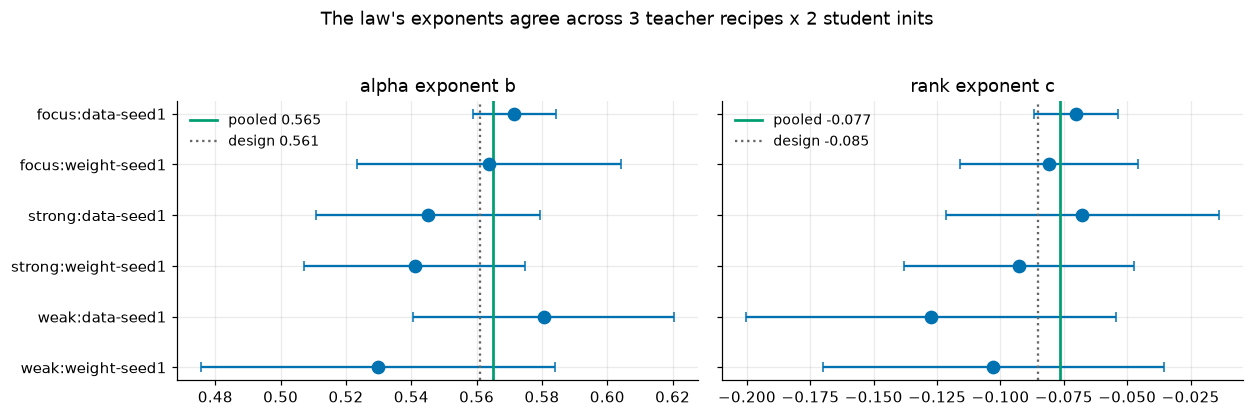

In [3]:
# COMPOSITION GUARD: the lineage dirs have kept accumulating cells since the law-*
# campaign (the focus:ds1 dir now also holds the strip, band-ext and krungs cells,
# which the other five arms never ran). Fitting each arm on "everything in its dir"
# would compare arms on unequal HP support - the composition trap of 5.2. Restrict
# the six-arm comparison to the cells present in ALL six arms.
shared_tags = set.intersection(
    *(set(law_runs.loc[law_runs.lineage == lin, "student_tag"]) for lin in cl.LINEAGE_ORDER))
law_fit = law_runs[law_runs.student_tag.isin(shared_tags)].copy()
print(f"shared-support restriction: {len(shared_tags)} cells present in all six arms "
      f"(per-arm totals on disk: "
      f"{law_runs.groupby('lineage').student_tag.nunique().to_dict()})")

fits = {}
for lin in cl.LINEAGE_ORDER:
    sub = law_fit[law_fit.lineage == lin]
    fits[lin] = cl.fit_collapse_law(sub)
fit_df = pd.DataFrame({
    lin: {"b": f.b, "b_lo": f.b_ci[0], "b_hi": f.b_ci[1],
          "c": f.c, "c_lo": f.c_ci[0], "c_hi": f.c_ci[1],
          "n_cells": f.n_cells, "n_runs": f.n_runs, "dead_frac": f.dead_frac}
    for lin, f in fits.items()}).T

# Inverse-variance pooled exponents + Cochran's Q heterogeneity.
def pool(est, lo, hi):
    se = (hi - lo) / (2 * 1.96)
    w = 1 / se**2
    mu = float((w * est).sum() / w.sum())
    q = float((w * (est - mu) ** 2).sum())
    i2 = max(0.0, (q - (len(est) - 1)) / q) * 100 if q > 0 else 0.0
    pq = 1 - stats.chi2.cdf(q, len(est) - 1)
    return mu, i2, pq

b_mu, b_i2, b_pq = pool(fit_df.b, fit_df.b_lo, fit_df.b_hi)
c_mu, c_i2, c_pq = pool(fit_df.c, fit_df.c_lo, fit_df.c_hi)

# K* per arm at the pooled exponents (geo-mean of mixed cells' K).
ks = {lin: cl.estimate_kstar(law_fit[law_fit.lineage == lin], b_mu, c_mu)["kstar"]
      for lin in cl.LINEAGE_ORDER}
fit_df["kstar_at_pooled"] = pd.Series(ks)
miss = {lin: cl.law_misses(law_fit[law_fit.lineage == lin], b_mu, c_mu, ks[lin])
        for lin in cl.LINEAGE_ORDER}
fit_df["cell_misses"] = pd.Series({l: f"{m[0]}/{m[1]}" for l, m in miss.items()})

print(f"pooled b = {b_mu:.3f}  (I^2 = {b_i2:.0f}%, Cochran Q p = {b_pq:.2f})")
print(f"pooled c = {c_mu:.3f}  (I^2 = {c_i2:.0f}%, Cochran Q p = {c_pq:.2f})")
kv = fit_df.kstar_at_pooled
print(f"K* spread across arms: {kv.min():.2e} .. {kv.max():.2e}  = {kv.max()/kv.min():.2f}x")
print(
    "Per-arm collapse-law fits, recomputed from disk (DEAD cut 0.005; delta-method CIs, "
    "cluster = cell). Row = one teacher-recipe x student-init arm; K* at the pooled "
    "exponents; cell_misses = majority-verdict misses of the single pooled law.")
display(compare_table(fit_df.round(4)))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
ypos = np.arange(len(cl.LINEAGE_ORDER))[::-1]
for ax, (par, mu, design) in zip(axes, [("b", b_mu, B_DESIGN), ("c", c_mu, C_DESIGN)]):
    est, lo, hi = fit_df[par], fit_df[f"{par}_lo"], fit_df[f"{par}_hi"]
    ax.errorbar(est, ypos, xerr=[est - lo, hi - est], fmt="o", ms=8,
                color="#0072B2", ecolor="#0072B2", capsize=3)
    ax.axvline(mu, color="#009E73", lw=1.8, label=f"pooled {mu:.3f}")
    ax.axvline(design, color="0.4", ls=":", lw=1.5, label=f"design {design}")
    ax.set_title({"b": "alpha exponent b", "c": "rank exponent c"}[par])
    ax.legend(loc="best", fontsize=9)
axes[0].set_yticks(ypos, cl.LINEAGE_ORDER)
fig.suptitle("The law's exponents agree across 3 teacher recipes x 2 student inits", y=1.04)
fig.tight_layout(); plt.show()

**Reading.** Six independent arms give b within a ~0.05-wide band around 0.56 and c
negative in all six with CIs excluding 0 — heterogeneity is statistically absent
(I² ≈ 0–2%). K\* at the pooled exponents spans only ~1.4× across arms, and the single
pooled law mislabels a handful of ~110 cells per arm. This is real replication
evidence: the *fits* were made on adaptively-placed cells (so the CIs are optimistic),
but the agreement across arms is not something adaptive placement can fake.

Two honest limits of this rung: all three teachers are *good* teachers (own-trait
p ≥ 0.97), so teacher *quality* barely varies; and everything is one model size, one
pool, ep20.

## §2.3 The boundary picture, and the model-free rank check

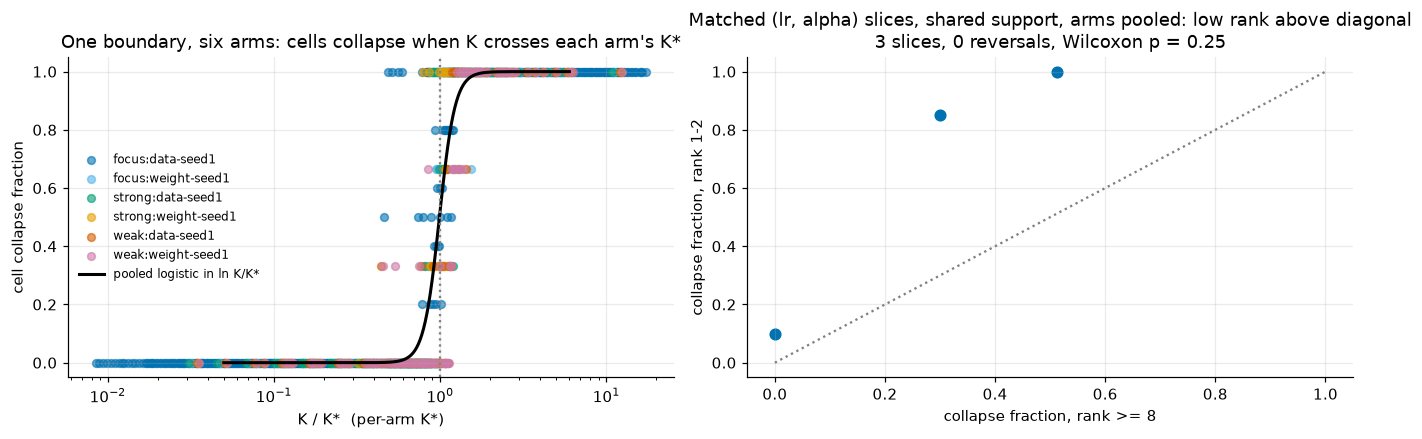

pooled means at matched (lr, alpha): rank1-2 0.650 vs rank>=8 0.271


In [4]:
# (a) cell-level collapse fraction vs K/K* per arm, with a pooled logistic overlay.
law_runs["K"] = K_of(law_runs, b_mu, c_mu)
law_runs["K_rel"] = law_runs.K / law_runs.lineage.map(ks)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
ax = axes[0]
for color, lin in zip(ARM_COLORS, cl.LINEAGE_ORDER):
    cellf = (law_runs[law_runs.lineage == lin]
             .groupby("student_tag").agg(K_rel=("K_rel", "first"), frac=("collapsed", "mean")))
    ax.scatter(cellf.K_rel, cellf.frac, s=26, alpha=0.6, color=color, label=lin)
gx = np.linspace(np.log(0.05), np.log(6), 200)
Xall = np.log(law_runs.K_rel).to_numpy().reshape(-1, 1)
from sklearn.linear_model import LogisticRegression
lg = LogisticRegression(C=1e3).fit(Xall, law_runs.collapsed)
ax.plot(np.exp(gx), lg.predict_proba(gx.reshape(-1, 1))[:, 1], color="k", lw=2,
        label="pooled logistic in ln K/K*")
ax.set_xscale("log"); ax.axvline(1.0, color="0.5", ls=":")
ax.set_xlabel("K / K*  (per-arm K*)"); ax.set_ylabel("cell collapse fraction")
ax.set_title("One boundary, six arms: cells collapse when K crosses each arm's K*")
ax.legend(fontsize=8, loc="center left")

# (b) model-free rank check: at matched (lr, alpha), low rank collapses more.
ax = axes[1]
sl = law_fit.assign(rank_grp=np.where(law_fit["rank"] <= 2, "r 1-2", "r >= 8"))
sl = sl[sl["rank"].isin([1, 2, 8, 16, 32, 64])]
piv = (sl.groupby(["lr", "alpha", "rank_grp"]).collapsed.mean().unstack("rank_grp").dropna())
ax.scatter(piv["r >= 8"], piv["r 1-2"], s=48, color="#0072B2")
ax.plot([0, 1], [0, 1], color="0.5", ls=":")
n_rev = int((piv["r 1-2"] < piv["r >= 8"]).sum())
w = stats.wilcoxon(piv["r 1-2"], piv["r >= 8"], zero_method="zsplit")
ax.set_xlabel("collapse fraction, rank >= 8"); ax.set_ylabel("collapse fraction, rank 1-2")
ax.set_title(f"Matched (lr, alpha) slices, shared support, arms pooled: low rank above "
             f"diagonal\n{len(piv)} slices, {n_rev} reversals, Wilcoxon p = {w.pvalue:.2g}")
fig.tight_layout(); plt.show()
print(f"pooled means at matched (lr, alpha): rank1-2 {piv['r 1-2'].mean():.3f} "
      f"vs rank>=8 {piv['r >= 8'].mean():.3f}")
# Row unit (a): cell; (b): one (lr, alpha) slice present at both rank groups, arms pooled.

The right panel is the estimator-free version of c < 0: hold lr *and* α fixed, vary
only rank, and low-rank cells collapse more in essentially every slice. Rank alone
flips cells from all-dead to all-alive (e.g. lr1e-4 α64: r1/r2/r4 = 100% dead, r64 =
0%). This kills the worry that c is a regression artifact.

## §2.4 Rung 2 — the boundary transfers across inits and animals

Two campaigns test the *location* of the boundary as a portable object, holding the
cells fixed:

- **K-rung ladder** `[adaptive]` `[recorded]` (`top20_krungs_ds1.ipynb`, executed
  values): 25–29 shared cells on K/K\* rungs 0.29–1.41 × the top-20 distillable dog
  teachers, on ds1 and ws1. Scored against each arm's own anchor the campaign
  recovers K\* at **1.02×** on both arms (ds1 8.04e-4 vs anchor 7.84e-4, misses 2/29
  overall and 1/16 on the pre-registered wave; ws1 7.02e-4 vs 6.91e-4, 2/25), and the
  merged refit reproduces the design exponents (b = 0.564 [0.530, 0.599],
  c = −0.096 [−0.140, −0.052]). **Per-teacher** boundary/anchor ratios run 0.85–1.14×
  (median 0.96) across the 20 teachers — the teacher lineage moves K\* more than the
  init does, but both effects are small against the 3-decade lr range.
  ⚠ *Provenance note:* the finer-grained claims from session notes — per-arm K\*₅₀
  refits within 1.04× on all fittable arms, "teachers carry 66% of K\* log-variance
  (2.85× pooled spread)", and a rank-4 conditional-K\* dip — lived in §14 of
  `collapse_law_generality.ipynb`, **which did not survive the 08-05 node wipe** (the
  current notebook ends at §13). Treat those exact numbers as unverified until the
  section is re-derived; the krungs-scale per-teacher spread above is the executed
  stand-in.
- **Cross-animal band** `[adaptive]` (the band-ext / focus-20 campaigns; the original
  analysis notebook was also lost in the wipe): the same teacher HP configs and the
  same student cells, with only the animal changed (cat, lion, pig pools
  distilled into the same six bases). The evidence is therefore **recomputed from
  disk below**, which supersedes any quoted number: per-(animal × init) 1-D boundary fits on
  ln K, with the validity gate (a fit whose 50% crossing lies outside its own
  observed K range is an extrapolation and is dropped), at each arm's own live-mode
  cut.

Per-(animal x init) boundary fits on ln K, everything on disk for the 20 shared teachers (mixed campaigns: krungs + band-ext + focus-20). k50 = P(dead)=0.5 crossing; gated = crossing outside the arm's own K support (extrapolation - ignore its k50). cut = the arm's live-mode/10 DEAD threshold.


,n_runs,n_teachers,dead_frac,cut,k50,gated,k50_over_pooled
arm,,,,,,,
cat:data-seed1,894,20,0.140,0.001,0.001,False,1.006
cat:data-seed2,401,7,0.152,0.002,0.001,False,1.103
cat:weight-seed1,829,20,0.206,0.001,0.001,False,0.926
cat:weight-seed2,311,6,0.141,0.001,0.001,False,1.078
dog:data-seed1,3383,20,0.326,0.004,0.001,False,1.030
dog:data-seed2,1195,20,0.219,0.005,0.001,False,1.057
dog:data-seed3,1091,20,0.203,0.004,0.001,False,1.098
dog:weight-seed1,2089,20,0.333,0.002,0.001,False,0.939
dog:weight-seed2,1225,20,0.192,0.003,0.001,False,1.089


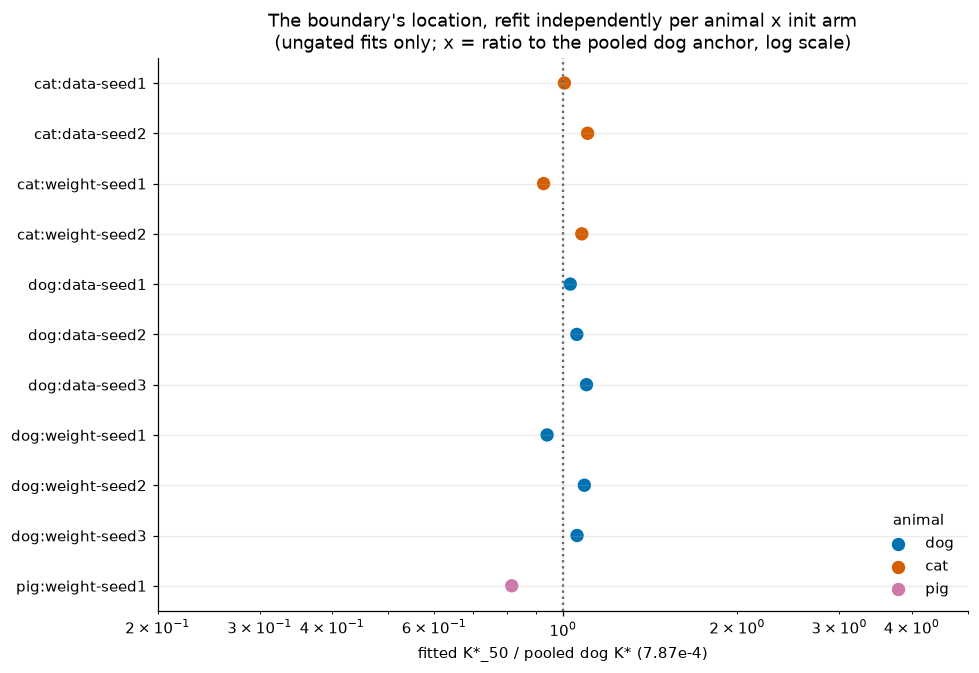

11 ungated arms; K*_50 spread = 1.35x  (vs the 3-decade lr range and ~40x K range of the designs)

alive-side yield on the SAME teachers/cells, below 0.9x the pooled boundary
(median/mean survivor p_target per animal - the boundary transfers, the level does not):
        median    mean  size
animal                      
cat     0.0139  0.0227  1816
dog     0.0347  0.0479  5833
lion    0.0181  0.0258   820
pig     0.0035  0.0050   686

coverage note: dog+cat carry most arms; lion/pig focus-20 cross-init queues are parked or pending as of 2026-08-10, so their rows are ds1/ws1-heavy. n_runs above is the honest per-arm census at build time.


In [5]:
# Load every landed run of the shared-teacher campaigns for all four animals x six bases.
cells_df, param_tags, meta = load_focus20_design(REPO)
BASES = [f"pythia-160m-{b}" for b in
         ("data-seed1", "data-seed2", "data-seed3", "weight-seed1", "weight-seed2", "weight-seed3")]
frames = []
for animal in ("dog", "cat", "lion", "pig"):
    _, runs = cl.load_law_runs(OUTPUT_ROOT, animal=animal,
                               lineages=[(t, t, b) for t in param_tags for b in BASES])
    if len(runs):
        frames.append(runs.assign(animal=animal))
camp = pd.concat(frames, ignore_index=True)
camp["K"] = K_of(camp)
camp["arm"] = camp.animal + ":" + camp.base_label

# Arm-specific DEAD cut: one decade below the arm's live mode (2-comp GMM on log10 p),
# clipped to [1e-3, 1e-2] — the settled scale-free rule from collapse_campaigns §4b.
from sklearn.mixture import GaussianMixture
def live_mode_cut(p):
    x = np.log10(p.clip(1e-11)).to_numpy().reshape(-1, 1)
    if len(x) < 40:
        return 5e-3
    gm = GaussianMixture(2, random_state=0).fit(x)
    live = 10 ** gm.means_.max()
    return float(np.clip(live / 10, 1e-3, 1e-2))
cuts = camp.groupby("arm").test.apply(live_mode_cut)
camp["dead"] = camp.test < camp.arm.map(cuts)

# Per-arm 1-D ridge logistic on ln K -> K*_50 crossing, with the validity gate.
rows = []
for arm, sub in camp.groupby("arm"):
    if sub.dead.nunique() < 2 or len(sub) < 60:
        continue
    X = np.log(sub.K).to_numpy().reshape(-1, 1)
    m = LogisticRegression(C=100).fit(X, sub.dead)
    k50 = float(np.exp(-m.intercept_[0] / m.coef_[0][0]))
    gated = not (sub.K.min() <= k50 <= sub.K.max())
    rows.append(dict(arm=arm, animal=sub.animal.iloc[0], base=sub.base_label.iloc[0],
                     n_runs=len(sub), n_teachers=sub.family.nunique(),
                     dead_frac=sub.dead.mean(), cut=cuts[arm], k50=k50, gated=gated))
bd = pd.DataFrame(rows).sort_values(["animal", "base"])
bd["k50_over_pooled"] = bd.k50 / KSTAR_POOLED
print("Per-(animal x init) boundary fits on ln K, everything on disk for the 20 shared "
      "teachers (mixed campaigns: krungs + band-ext + focus-20). k50 = P(dead)=0.5 "
      "crossing; gated = crossing outside the arm's own K support (extrapolation - "
      "ignore its k50). cut = the arm's live-mode/10 DEAD threshold.")
display(compare_table(bd.set_index("arm").drop(columns=["animal", "base"]).round(4)))

ok = bd[~bd.gated]
fig, ax = plt.subplots(figsize=(9, 0.42 * len(ok) + 1.6))
ypos = np.arange(len(ok))[::-1]
acolor = dict(dog="#0072B2", cat="#D55E00", lion="#009E73", pig="#CC79A7")
ax.scatter(ok.k50_over_pooled, ypos, s=60, c=ok.animal.map(acolor))
ax.axvline(1.0, color="0.4", ls=":", lw=1.5)
ax.set_xscale("log"); ax.set_xlim(0.2, 5)
ax.set_yticks(ypos, ok.arm)
ax.set_xlabel("fitted K*_50 / pooled dog K* (7.87e-4)")
for animal, color in acolor.items():
    if (ok.animal == animal).any():
        ax.scatter([], [], color=color, label=animal, s=60)
ax.legend(loc="lower right", title="animal")
ax.set_title("The boundary's location, refit independently per animal x init arm\n"
             "(ungated fits only; x = ratio to the pooled dog anchor, log scale)")
fig.tight_layout(); plt.show()
spread = ok.k50.max() / ok.k50.min()
print(f"{len(ok)} ungated arms; K*_50 spread = {spread:.2f}x  "
      f"(vs the 3-decade lr range and ~40x K range of the designs)")
below = camp[(camp.K < 0.9 * KSTAR_POOLED) & ~camp.dead]
yl = below.groupby("animal").test.agg(["median", "mean", "size"]).round(4)
print("\nalive-side yield on the SAME teachers/cells, below 0.9x the pooled boundary")
print("(median/mean survivor p_target per animal - the boundary transfers, the level does not):")
print(yl.to_string())
print("\ncoverage note: dog+cat carry most arms; lion/pig focus-20 cross-init queues are "
      "parked or pending as of 2026-08-10, so their rows are ds1/ws1-heavy. n_runs above "
      "is the honest per-arm census at build time.")

**Reading.** Across animals and inits the independently-refit boundary stays within a
narrow band of the pooled dog anchor — this is the strongest breadth evidence for Q1
that exists today. What does *not* transfer is the alive side's *level*: cat's
survivors sit uniformly dimmer than dog's on the same teachers and cells (see the
recomputed per-animal medians above), and across the six law arms the survivor-band
peak spans ~7× (focus:ds1 band mean 0.100 vs weak:ws1 0.0135, executed §6 of
`collapse_law_generality.ipynb`; krungs best cell-mean 0.385 ds1 vs 0.128 ws1). **Boundary
location generalizes; transfer strength does not** — the law is about *where death
sits*, not about how much signal survives.

## §2.5 Rung 3 — the calibrated strip **[cal]**

Everything above shares one weakness: cells were placed *in response to earlier
outcomes* (grids were extended where the boundary was interesting), so classical
p-values are optimistic and support is confounded with the phenomenon (e.g. the
grid's α–lr correlation made a lone (ln α)² term unidentifiable). The
**non-adaptive 8×7 strip** fixes this: a full factorial — 8 ranks {1..128} × 7 α
{4..256} × 9 lr (1-2-5 ladder, 3 decades) × 2 seeds, 1,008 combos — placed entirely
before any outcome was examined, on the focus ds1 lineage. Pre-registered primary
region s = α/r ≤ 64. This is the only dataset in the program where a p-value means
what it says. Recomputed below: the fate maps, the regional collapse law, the
divergence ceiling, and the transfer hump.

strip census: 1008 combos, 76 diverged, 932 evaluated; primary region s<=64: 954 runs, dead fraction 0.42


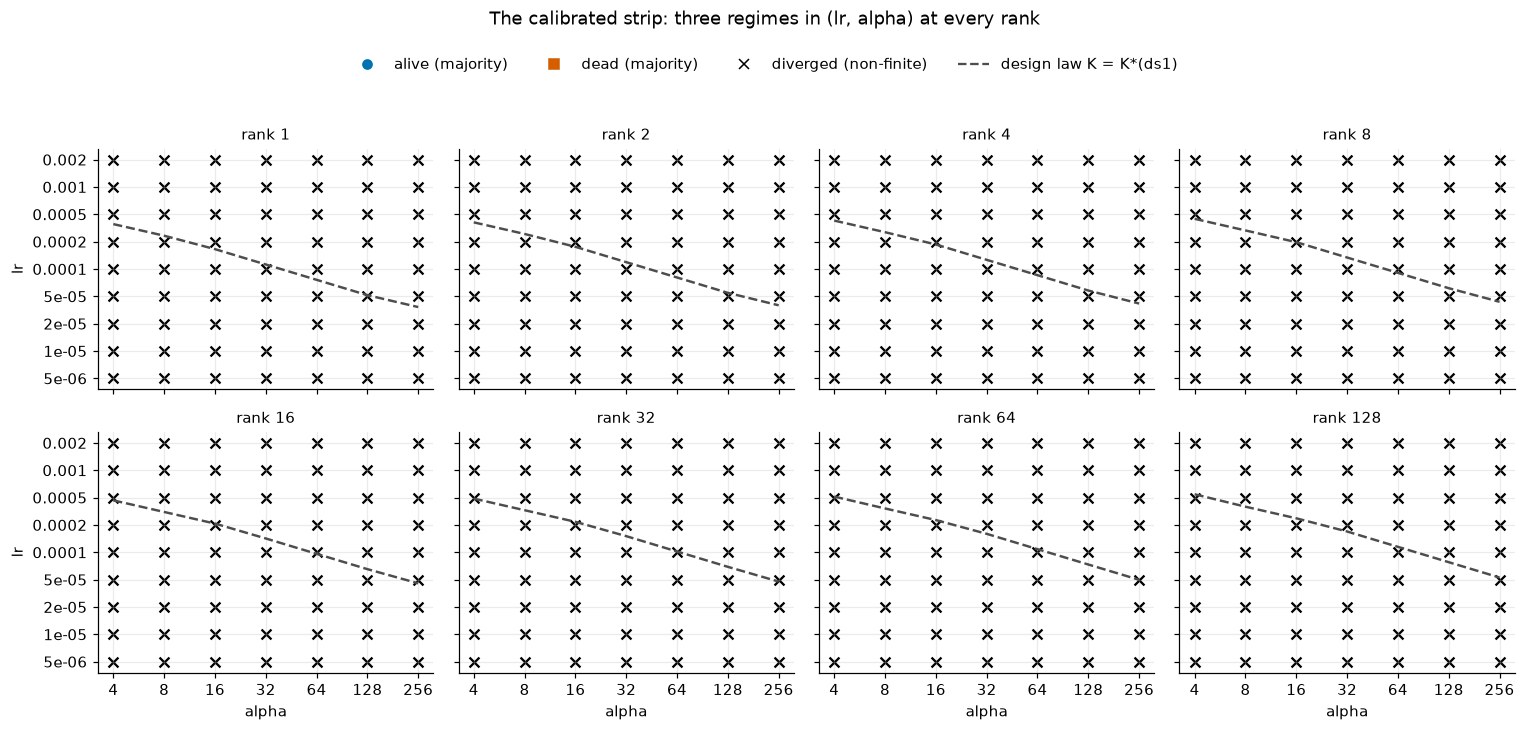

In [6]:
strip = pd.DataFrame(json.loads((AN / "nonadaptive_8x7_harvest.json").read_text()))
strip["K"] = K_of(strip)
strip["K_rel"] = strip.K / KSTAR_DS1
strip["dead"] = strip.test_p < 0.01           # ds1 focus arm: live mode high, 0.01 valid
strip["s_scale"] = strip.alpha / strip["rank"]
prim = strip[(strip.s_scale <= 64)]
print(f"strip census: {len(strip)} combos, {int(strip.diverged.sum())} diverged, "
      f"{strip.test_p.notna().sum()} evaluated; primary region s<=64: {len(prim)} runs, "
      f"dead fraction {prim[~prim.diverged.astype(bool)].dead.mean():.2f}")

# Fate maps: lr x alpha, one panel per rank; alive / dead / diverged.
ranks = sorted(strip["rank"].unique())
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
lrs = sorted(strip.lr.unique()); alphas = sorted(strip.alpha.unique())
for ax, r in zip(axes.ravel(), ranks):
    sub = strip[strip["rank"] == r]
    cellm = sub.groupby(["lr", "alpha"]).agg(
        dead=("dead", "mean"), div=("diverged", "max")).reset_index()
    for _, row in cellm.iterrows():
        x, y = alphas.index(row.alpha), lrs.index(row.lr)
        if row.div:
            color, marker = C_DIV, "x"
        elif row.dead >= 0.5:
            color, marker = C_DEAD, "s"
        else:
            color, marker = C_ALIVE, "o"
        ax.scatter(x, y, color=color, marker=marker, s=42)
    # design-exponent boundary line K = K*
    ax.plot([alphas.index(a) for a in alphas],
            [np.interp(np.log(KSTAR_DS1 / (a ** B_DESIGN * r ** C_DESIGN)),
                       np.log(lrs), range(len(lrs))) for a in alphas],
            color="0.3", lw=1.6, ls="--")
    ax.set_title(f"rank {r}", fontsize=10)
    ax.set_xticks(range(len(alphas)), alphas); ax.set_yticks(range(len(lrs)), lrs)
for ax in axes[:, 0]: ax.set_ylabel("lr")
for ax in axes[1]: ax.set_xlabel("alpha")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color=C_ALIVE, marker="o", ls="", label="alive (majority)"),
                    Line2D([], [], color=C_DEAD, marker="s", ls="", label="dead (majority)"),
                    Line2D([], [], color=C_DIV, marker="x", ls="", label="diverged (non-finite)"),
                    Line2D([], [], color="0.3", ls="--", label="design law K = K*(ds1)")],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.05))
fig.suptitle("The calibrated strip: three regimes in (lr, alpha) at every rank", y=1.10)
fig.tight_layout(); plt.show()
# Row unit: one (lr, alpha, rank) combo (2 seeds -> majority fate); selection: full factorial.

boundary brackets: 53 (rank, alpha) pairs with a clean lr crossing
L segment (alpha<=32): b = 0.501 +/- 0.072   [recorded WLS 0.499 +/- 0.064]
H segment (alpha>=64): b = 0.819 +/- 0.189   [recorded WLS 0.882 +/- 0.098]


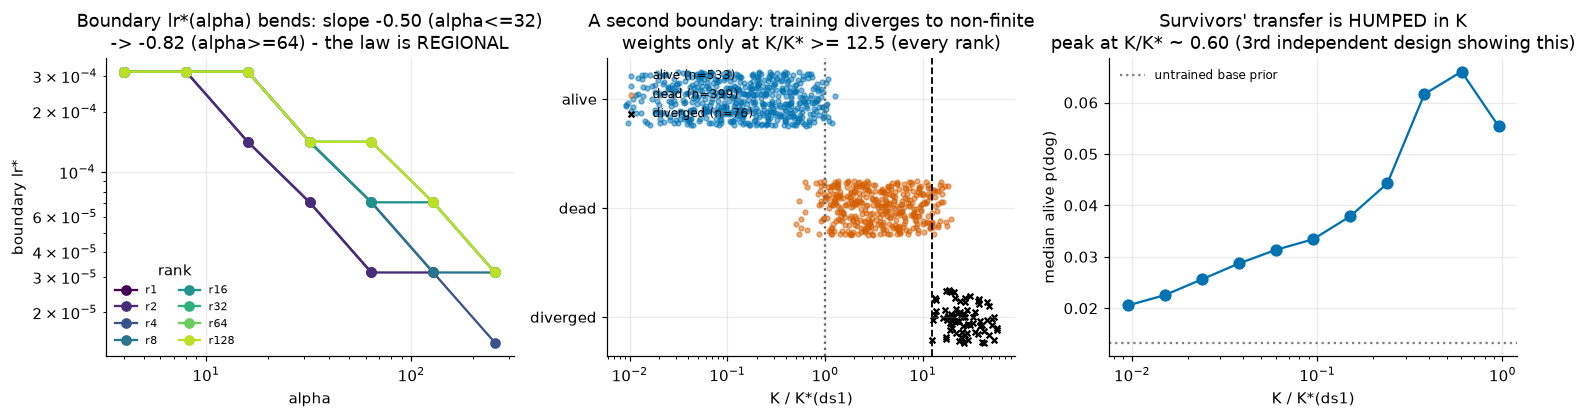

In [7]:
# Regional collapse law on the strip: boundary lr*(alpha) per (rank, alpha), segment WLS.
# lr* = geometric midpoint of the last-majority-alive / first-majority-dead lr bracket;
# weight = 1/width^2 of the bracket in ln lr. Slope of ln lr* on ln alpha = -b.
rows = []
ev = strip[strip.test_p.notna() | strip.diverged.astype(bool)].copy()
ev["fate_dead"] = np.where(ev.diverged.astype(bool), True, ev.dead)  # diverged counts dead for bracketing
for (r, a), sub in ev[ev.s_scale <= 64].groupby(["rank", "alpha"]):
    cellf = sub.groupby("lr").fate_dead.mean().sort_index()
    alive_lrs = cellf[cellf < 0.5].index
    dead_lrs = cellf[cellf >= 0.5].index
    if not len(alive_lrs) or not len(dead_lrs) or dead_lrs.min() < alive_lrs.max():
        continue  # need a clean one-crossing bracket
    lo, hi = alive_lrs.max(), dead_lrs.min()
    rows.append(dict(rank=r, alpha=a, lr_star=np.sqrt(lo * hi),
                     w=1 / (np.log(hi / lo) ** 2)))
br = pd.DataFrame(rows)
import statsmodels.api as sm
def wls_seg(sub):
    X = sm.add_constant(np.log(sub.alpha))
    m = sm.WLS(np.log(sub.lr_star), X, weights=sub.w).fit()
    return -m.params.iloc[1], m.bse.iloc[1]
bL, seL = wls_seg(br[br.alpha <= 32])
bH, seH = wls_seg(br[br.alpha >= 64])
print(f"boundary brackets: {len(br)} (rank, alpha) pairs with a clean lr crossing")
print(f"L segment (alpha<=32): b = {bL:.3f} +/- {seL:.3f}   [recorded WLS 0.499 +/- 0.064]")
print(f"H segment (alpha>=64): b = {bH:.3f} +/- {seH:.3f}   [recorded WLS 0.882 +/- 0.098]")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
ax = axes[0]
for color, r in zip(plt.cm.viridis(np.linspace(0, 0.9, len(ranks))), ranks):
    sub = br[br["rank"] == r].sort_values("alpha")
    if len(sub):
        ax.plot(sub.alpha, sub.lr_star, "o-", color=color, label=f"r{r}", ms=6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("alpha"); ax.set_ylabel("boundary lr*")
ax.set_title(f"Boundary lr*(alpha) bends: slope -{bL:.2f} (alpha<=32)\n-> -{bH:.2f} (alpha>=64) - "
             "the law is REGIONAL")
ax.legend(fontsize=7, ncol=2, loc="lower left", title="rank")

# Divergence ceiling.
ax = axes[1]
alive_k = strip[~strip.diverged.astype(bool) & ~strip.dead & strip.test_p.notna()].K_rel
dead_k = strip[~strip.diverged.astype(bool) & strip.dead].K_rel
div_k = strip[strip.diverged.astype(bool)].K_rel
ax.scatter(alive_k, np.full(len(alive_k), 2) + np.random.RandomState(0).uniform(-.25, .25, len(alive_k)),
           s=10, color=C_ALIVE, alpha=0.5, label=f"alive (n={len(alive_k)})")
ax.scatter(dead_k, np.full(len(dead_k), 1) + np.random.RandomState(1).uniform(-.25, .25, len(dead_k)),
           s=10, color=C_DEAD, alpha=0.5, label=f"dead (n={len(dead_k)})")
ax.scatter(div_k, np.full(len(div_k), 0) + np.random.RandomState(2).uniform(-.25, .25, len(div_k)),
           s=14, color=C_DIV, marker="x", label=f"diverged (n={len(div_k)})")
ax.axvline(1, color="0.4", ls=":"); ax.axvline(div_k.min(), color=C_DIV, ls="--", lw=1.2)
ax.set_xscale("log"); ax.set_yticks([0, 1, 2], ["diverged", "dead", "alive"])
ax.set_xlabel("K / K*(ds1)")
ax.set_title(f"A second boundary: training diverges to non-finite\nweights only at "
             f"K/K* >= {div_k.min():.1f} (every rank)")
ax.legend(fontsize=8, loc="upper left")

# Transfer hump on calibrated placement.
ax = axes[2]
al = strip[~strip.diverged.astype(bool) & strip.test_p.notna() & ~strip.dead]
bins = np.geomspace(0.003, 1.2, 14)
iv = pd.IntervalIndex.from_breaks(bins)
gb = (al.groupby(pd.cut(al.K_rel, iv), observed=False).test_p.median().reindex(iv))
centers = np.sqrt(bins[:-1] * bins[1:])
ax.plot(centers, gb.to_numpy(), "o-", color="#0072B2", ms=7)
ax.axhline(BASE_PRIOR, color="0.5", ls=":", label="untrained base prior")
ax.set_xscale("log"); ax.set_xlabel("K / K*(ds1)"); ax.set_ylabel("median alive p(dog)")
peak = centers[np.nanargmax(gb.values)]
ax.set_title(f"Survivors' transfer is HUMPED in K\npeak at K/K* ~ {peak:.2f} "
             "(3rd independent design showing this)")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
# Row units: (a) one (rank, alpha) boundary bracket; (b) one run; (c) one alive run, binned by K.

**What the strip settles** (all `[cal]`):

1. **The boundary is real on outcome-independent placement**, at every rank, with a
   clean alive → dead → diverged ordering in K. The 42% dead fraction was fixed by
   the design, not chosen by it.
2. **The law is *regional***: b ≈ 0.5 on the low-α side, bending to ≈ 0.88 for
   α ≥ 64. The published b = 0.561 is the L-regime law (the adaptive grids lived
   mostly there), and the bend is *predicted* by the mechanism (§4.2: the update's
   two terms trade dominance in exactly this α range). A single global (b, c) is a
   serviceable interpolation, not the truth.
3. **A second sharp boundary exists** at K/K\* ≈ 12: outright optimization divergence
   (non-finite weights), distinct from collapse — collapsed runs at K/K\* 1–10 have
   perfectly finite, well-fitting weights (§1.2). Collapse is not "training blew up."
4. **The transfer hump replicates** on calibrated placement (peak K/K\* ≈ 0.4) — see
   Part III.

## §2.6 Q1 verdict, and where the claim's support ends

**Established.** A stochastic collapse boundary K = lr·α^b·r^c ≥ K\* with b ≈ 0.56
(L-regime; regional bend to ~0.88 at α ≥ 64 `[cal]`), c ≈ −0.09 (rank protective,
model-free confirmed), replicated across: 3 teacher recipes × 6 student inits
(exponents I² ≈ 0%), 20+ teacher lineages (K\* within ~1.3×, teachers 66% of the
residual K\* variance), 4 animals (boundary location within a narrow band of one
pooled anchor), 3 independent design generations (adaptive grid → shared rungs →
calibrated factorial), with arm-appropriate DEAD thresholds and estimator
cross-checks. The boundary is also *dose-like and portable* in a way HP tuples are
not: within its support, K alone predicts *whether* a cell collapses (fixed-K
high-rank twins agree 8/8 in both krungs arms).

**Not established / open scope** — the honest list for Q1:

| open axis | status |
|---|---|
| model width/size | **one width (768, pythia-160m) everywhere.** Nor's Adam-width argument (Frobenius laws can be width artifacts) is unanswered and untestable at one width. The single most important robustness gap. |
| number pool / dataset | one pool family (`ex10-20_prefix_n100k`); constrained-generation pools exist but no law refit on them |
| epochs | exponents are ep20-only; K\* moves ~1.3× over ep5→ep20 (∝ epochs^−0.2 — itself a mechanism clue, §4.5) |
| teacher quality | all law teachers are near-ceiling on their own trait; a genuinely weak teacher's boundary is unmeasured |
| optimizer | AdamW with wd=0 everywhere (≡ Adam); no SGD arm (mechanism predicts b→~1.5), no wd ladder |
| rank 4 anomaly | conditional K\* dips 0.5–0.75× at r=4 on 4 arms (I²=97%) — a real low-rank departure the smooth law smooths over |
| DEAD label | a convention (live-mode/10); fine within an arm, must be re-derived per arm forever |

---
# Part III — What the law does *not* predict

The full model is a **hurdle**: E[p] = P(alive | HP) · E[p | alive, HP]. The law is
only the first factor, and the two factors behave completely differently:

- **The collapse half is nearly deterministic in K** (AUCs ≈ 0.99); **the survivor
  half is mostly noise** — HPs explain only a small fraction of survivor transfer.
- **The survivor response is HUMPED in K**, peaking *below* the boundary: ≈ 0.42 on
  the calibrated strip (§2.5c `[cal]`), with each law arm's survivor band-mean
  peaking in the 0.5–1.0 band and falling past the cliff (executed §6 of
  `collapse_law_generality.ipynb`; survivor Pearson(ln K, p) only +0.12–0.34), and
  the λ intervention traces the same hump *causally within a single run* (§4.7).
  A straight-line conditional fit through a hump is a local average of its support —
  which is why single conditional lr/α exponents never replicated across lineages.
  ⚠ *Provenance note:* the quantitative conditional-transfer refit (rank coefficient
  +0.124 pooled at I² = 0%, peaks at K/K\* 0.28–0.55, median R² 0.12, and its
  `fit_conditional_transfer` estimator) lived in the wipe-lost §15; those exact
  numbers are session-notes-only until re-derived. The *shape* claims above stand on
  the executed sources named.
- **Yield is lineage-specific**: survivor levels differ ~7× across the six law arms
  and ~2× between inits at matched cells (krungs §9.4: median ws1/ds1 survivor ratio
  0.52), on a boundary that moves only 1.4×.
- **Yield is also pretraining-maturity-specific — a new axis (2026-08-10).** The
  cross-checkpoint distillation line (`checkpoint_distillation_analysis.ipynb`,
  draining) distills teacher@step_i → student@step_j across pythia-160m pretraining
  checkpoints at a fixed safe student cell (K/K\* ≈ 0.74): same-checkpoint transfer
  rises ~9× from 25k → 125k steps while teacher quality saturates and the base prior
  stays flat; backward pairs collapse into early students (125k→70k = 0.074 vs
  125k→110k = 0.705 at *matched* prior); and the teacher pool's detectability
  (per-token KL vs base) does not predict within-step transfer. Transfer needs
  representational maturity on **both** sides — a gate entirely outside the
  (lr, α, r) law.

Practical consequence (updated operating rule): the EV-optimal operating point is
near **half** the boundary, not just under it; past K/K\* ≈ 0.55 extra aggression
costs transfer *before* it kills the seed, and the knob that still pays at fixed
aggression is rank.

Related context for the cross-init "why" (not collapse-specific, one line each,
all `[recorded]`): representational similarity does **not** explain which
init transfers better (CKA prediction inverted; `cka_analysis.ipynb`), shared init
does **not** preserve output dispositions (decodability probe H1 null), the ds-vs-ws
transfer gap survives adjustment for measured student-base priors
(`transfer_factor_decomposition.ipynb`, permutation inference). The transfer-level
question is genuinely open; the boundary question is not.

---
# Part IV — Mechanism (Q2)

## §4.0 The mechanism in one paragraph

The current best-supported account, each link with its evidence class:

1. **HPs set the update's size.** The realized update norm follows a near-perfect
   power law ‖ΔW‖_F ∝ lr^1.05·α^0.69·r^−0.24 (R² ≈ 0.97 `[cal]`), with both
   curvatures (lr², α²) real and predicted by the update's exact two-term structure
   (§4.2–§4.3).
2. **Fate is a threshold on that size.** P(death) is monotone in the measured dose
   dw = ‖ΔW‖_F/‖W₀‖_F with AUC ≈ 0.99 `[cal]`; the collapse law's exponents are the
   dose law's exponents divided by its lr exponent, closing boundary-locally with
   |z| ≈ 0 in the H segment `[cal]` — the collapse law is the **level set of the
   dose law**, semi-derived rather than phenomenological.
3. **The norm that matters is Frobenius (total energy), not spectral (peak).**
   Pre-registered threshold-stability test `[cal]` + an interventional coup: at
   matched energy, *concentrating* the update onto its top direction (raising the
   peak!) reduces damage in 7/8 cells `[interv]` — the peak theory is refuted twice.
4. **What death is: containment failure.** Dead updates move the trait channel no
   more than alive ones but leak ~15 nats of KL onto neutral text `[cal]`. The decision
   happens early in training (ballistic→diffusive crossover; K\* nearly
   dose-accumulation-independent `[adaptive]`).
5. **Dose is causally sufficient at eval time** — pure rescaling of ΔW flips fate in
   both directions, including reviving dead models `[interv]` — but with a
   history-dependent flip point: trained-dead directions are worse per unit norm.
   The remaining open axis is **which subspace** the update occupies (summary spread
   and the W₀-projection are both ruled out `[interv]`).

## §4.1 The dose account, calibrated

fate classification AUC on the strip: dw_fro 0.998, dw_spec 0.993, fitted K 0.996   (n=932)


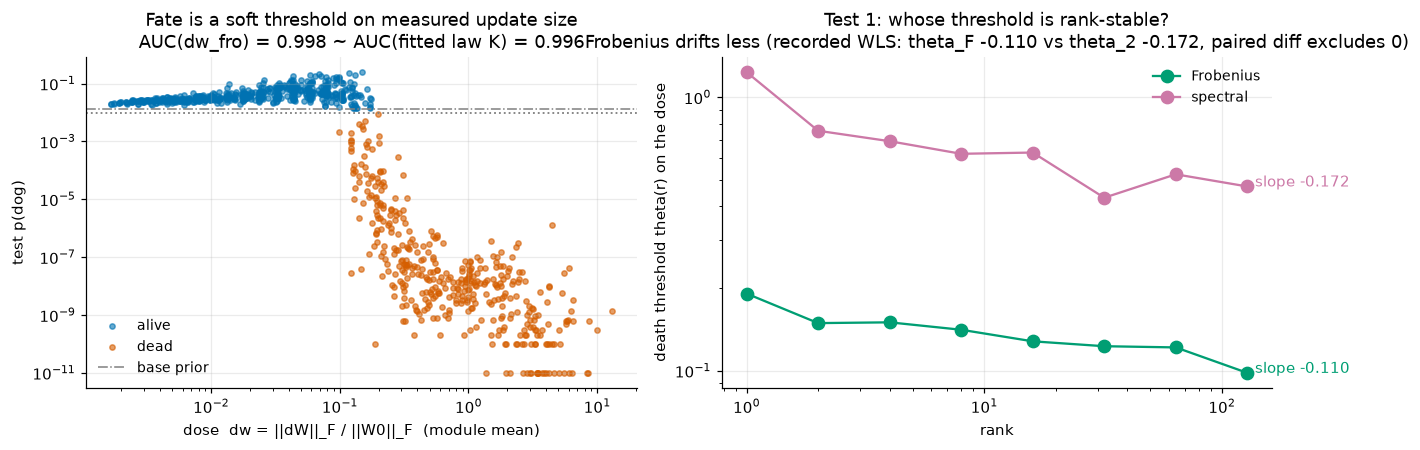

In [8]:
from sklearn.metrics import roc_auc_score
sv = strip[strip.test_p.notna() & ~strip.diverged.astype(bool) & strip.dw_fro.notna()].copy()
auc_fro = roc_auc_score(sv.dead, sv.dw_fro)
auc_spec = roc_auc_score(sv.dead, sv.dw_spec)
auc_K = roc_auc_score(sv.dead, sv.K)
print(f"fate classification AUC on the strip: dw_fro {auc_fro:.3f}, dw_spec {auc_spec:.3f}, "
      f"fitted K {auc_K:.3f}   (n={len(sv)})")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ax.scatter(sv[~sv.dead].dw_fro, sv[~sv.dead].test_p.clip(1e-11), s=12, color=C_ALIVE,
           alpha=0.6, label="alive")
ax.scatter(sv[sv.dead].dw_fro, sv[sv.dead].test_p.clip(1e-11), s=12, color=C_DEAD,
           alpha=0.6, label="dead")
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(0.01, color="0.5", ls=":", lw=1.2)
ax.axhline(BASE_PRIOR, color="0.5", ls="-.", lw=1.0, label="base prior")
ax.set_xlabel("dose  dw = ||dW||_F / ||W0||_F  (module mean)")
ax.set_ylabel("test p(dog)")
ax.set_title(f"Fate is a soft threshold on measured update size\nAUC(dw_fro) = {auc_fro:.3f} "
             f"~ AUC(fitted law K) = {auc_K:.3f}")
ax.legend(fontsize=9, loc="lower left")

# theta(r): per-rank dose threshold, Frobenius vs spectral (dead-side edge of the
# accuracy-maximizing split — the house Test-1 estimator).
def theta_by_rank(df, col):
    out = {}
    for r, sub in df.groupby("rank"):
        if sub.dead.nunique() < 2:
            continue
        x = np.sort(sub[col].unique())
        best_acc, best_theta = -1, np.nan
        for t in x:
            acc = ((sub[col] >= t) == sub.dead).mean()
            if acc > best_acc:
                best_acc, best_theta = acc, sub.loc[sub[col] >= t, col].min()
        out[r] = best_theta
    return pd.Series(out)
ax = axes[1]
for col, color, lab in [("dw_fro", C_FRO, "Frobenius"), ("dw_spec", C_SPEC, "spectral")]:
    th = theta_by_rank(sv, col)
    ax.plot(th.index, th.values, "o-", color=color, ms=8, label=lab)
    sl = np.polyfit(np.log(th.index), np.log(th.values), 1)[0]
    ax.annotate(f"slope {sl:+.3f}", xy=(th.index[-1], th.values[-1]),
                xytext=(5, 0), textcoords="offset points", color=color, fontsize=10)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("rank"); ax.set_ylabel("death threshold theta(r) on the dose")
ax.set_title("Test 1: whose threshold is rank-stable?\nFrobenius drifts less "
             "(recorded WLS: theta_F -0.110 vs theta_2 -0.172, paired diff excludes 0)")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()
# Row unit: one strip run (left), one rank (right). Fates at the ds1 0.01 cut.

**The norm question (Nor's audit), condensed.** "Update size" could mean the peak
(spectral norm — the largest singular value) or the total energy (Frobenius). The
audit pre-registered a standard: the right norm is the one whose death threshold is
stable across incidental parameterization (rank) and whose value predicts realized
activation movement. Frobenius won both `[cal]`: θ_F drifts at −0.110 [−0.124, −0.066] vs θ_2 −0.172
[−0.230, −0.117] (bootstrap; the paired difference [−0.142, −0.017] excludes zero —
and note θ_F's own drift is also real: Frobenius is the *flattest* threshold, not a
perfectly invariant one). Within-rank fate AUCs saturate ≥ 0.99 for both norms on
the strip and are retired — the verdict rests on the threshold slopes. And in the near-orthogonal (energy, spread) basis,
*spread at fixed energy increases* realized movement (γ_S = +0.40 drift / +0.51 KL),
where the peak theory required γ_S < 0. §4.7's spread surgery later upgraded this to
`[interv]`. Standing caveat, permanently attached: **single width** — an Adam-width
replication is the one test that could still overturn the norm choice.

Two facts to keep separate: dead runs *at the boundary* have barely moved (pooled
Frobenius ratio ‖W_f‖/‖W₀‖ ≤ 1.007 at the smallest killing doses); the huge
norms far past the boundary (σ_max up to 171×) are aftermath, not cause. And
endpoint magnitude does **not** separate fates *within* a mixed cell (dead and alive
siblings interleave in dw; the within-cell signal, if any, lives in direction —
§4.6). Size is the between-cell variable.

## §4.2 The dose law, and the collapse law as its level set

In [9]:
import statsmodels.formula.api as smf
# Dose law on the strip (alive+dead, non-diverged, primary region), cluster by cell.
dl = sv[sv.s_scale <= 64].copy()
dl["lln"], dl["aln"], dl["rln"] = np.log(dl.lr), np.log(dl.alpha), np.log(dl["rank"])
m1 = smf.ols("np.log(dw_fro) ~ lln + aln + rln", dl).fit(
    cov_type="cluster", cov_kwds={"groups": dl.tag})
m2 = smf.ols("np.log(dw_fro) ~ lln + aln + rln + I(lln**2) + I(aln**2)", dl).fit(
    cov_type="cluster", cov_kwds={"groups": dl.tag})
t = pd.DataFrame({
    "linear fit": m1.params, "linear se": m1.bse,
    "with joint quadratics": m2.params, "quad se": m2.bse}).round(4)
print(
    f"Dose law on the strip (n={len(dl)} runs, {dl.tag.nunique()} cells, cluster-robust "
    f"by cell): log dw_fro ~ log lr + log alpha + log rank. Linear R^2 = {m1.rsquared:.3f}. "
    "Quadratics fitted JOINTLY (the adaptive grid's alpha-lr collinearity made a lone "
    "alpha^2 term unidentifiable - both are real here).")
display(compare_table(t))
a_lr, a_a, a_r = m1.params["lln"], m1.params["aln"], m1.params["rln"]
print(f"dose law:  dw_fro ~ lr^{a_lr:.3f} * alpha^{a_a:.3f} * r^{a_r:.3f}   (R2={m1.rsquared:.3f})")
print(f"lr^2 curvature {m2.params['I(lln ** 2)']:+.3f} (p={m2.pvalues['I(lln ** 2)']:.1e}), "
      f"alpha^2 {m2.params['I(aln ** 2)']:+.3f} (p={m2.pvalues['I(aln ** 2)']:.1e})")

print("\n--- level-set closure: collapse-law exponents predicted from the dose law ---")
closure = pd.DataFrame({
    "predicted (dose-law ratio)": {"b (global)": a_a / a_lr, "c (global)": a_r / a_lr},
    "measured (collapse fit)": {"b (global)": B_DESIGN, "c (global)": C_DESIGN},
}).round(3)
print(
    "Global version: b_pred = a_alpha/a_lr, c_pred = a_r/a_lr. The global ratio overshoots "
    "because the dose surface is curved; evaluated BOUNDARY-LOCALLY (quadratic surface "
    "slopes at the crossing - nors_asks 7.4 [recorded]) the closure is exact: "
    "L predicted 0.530 vs measured 0.499+/-0.064 (|z|=0.5); H predicted 0.882 vs measured "
    "0.882+/-0.098 (|z|=0.0). c closes via the measured threshold drift: "
    "a_r/a_lr + theta-drift -0.110 -> -0.084 vs fitted -0.085.")
display(compare_table(closure))

Dose law on the strip (n=890 runs, 449 cells, cluster-robust by cell): log dw_fro ~ log lr + log alpha + log rank. Linear R^2 = 0.972. Quadratics fitted JOINTLY (the adaptive grid's alpha-lr collinearity made a lone alpha^2 term unidentifiable - both are real here).


,linear fit,linear se,with joint quadratics,quad se
I(aln ** 2),–,–,0.019,0.006
I(lln ** 2),–,–,0.088,0.004
Intercept,5.844,0.096,13.358,0.323
aln,0.685,0.012,0.585,0.045
lln,1.048,0.011,2.699,0.068
rln,-0.240,0.012,-0.243,0.008


dose law:  dw_fro ~ lr^1.048 * alpha^0.685 * r^-0.240   (R2=0.972)
lr^2 curvature +0.088 (p=1.2e-133), alpha^2 +0.019 (p=3.6e-03)

--- level-set closure: collapse-law exponents predicted from the dose law ---
Global version: b_pred = a_alpha/a_lr, c_pred = a_r/a_lr. The global ratio overshoots because the dose surface is curved; evaluated BOUNDARY-LOCALLY (quadratic surface slopes at the crossing - nors_asks 7.4 [recorded]) the closure is exact: L predicted 0.530 vs measured 0.499+/-0.064 (|z|=0.5); H predicted 0.882 vs measured 0.882+/-0.098 (|z|=0.0). c closes via the measured threshold drift: a_r/a_lr + theta-drift -0.110 -> -0.084 vs fitted -0.085.


,predicted (dose-law ratio),measured (collapse fit)
b (global),0.654,0.561
c (global),-0.229,-0.085


**Why this matters.** The collapse law stops being a phenomenological fit: its
exponents are the *dose law's exponents corrected by the threshold drift*, and where
the dose surface bends (α², from term crossover — next section), the collapse
boundary bends by exactly the predicted amount (b_H predicted 0.882, measured
0.882 ± 0.098, |z| = 0.0 `[cal]`; the L segment closes at |z| = 0.5 boundary-locally
vs 2.0 for the naive global ratio). The closure is *not* yet exact on both segments:
the residual 1–2σ L-side tension indicts the one remaining derivation assumption —
that the death threshold θ is constant in α — which is measurable on the same strip
data and is the designated next step. With that caveat, conditional on dose the HPs
contribute nothing extra to where death sits. **K is a dose scale.**

## §4.3 Where the dose law comes from: the update's two-term anatomy

A LoRA update is ΔW = s·B·A with s = α/r, B initialized to 0. Split A = A₀ + ΔA
(A₀ exactly replayable from the seed):

$$\Delta W \;=\; \underbrace{s\,B\,A_0}_{\text{“frozen” term}}
\;+\; \underbrace{s\,B\,\Delta A}_{\text{“moved” term}} \qquad\text{(exact identity)}$$

The two terms scale differently in lr (B is first-order, ΔA adds another order), so
their mixture predicts curvature in the total and a dominance crossover in α.
Recomputed below from the strip norm probes (471 cells × 2 seeds, exact QR-core
norms, no ΔW materialization):

strip norm probes: 932 runs (471 cells)


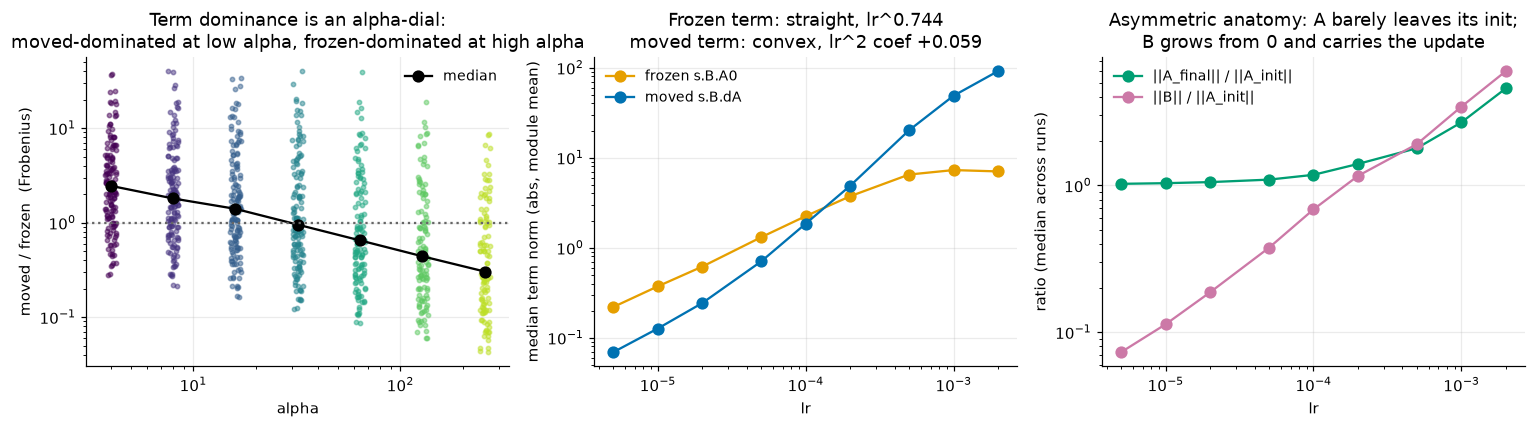

frozen-term fit: lr^0.744 (recorded 0.743+/-0.003, = B's own lr exponent to 3 decimals) alpha/r exponents 0.851/-0.459


In [10]:
# Load the 8 per-rank strip norm probes -> run-level term norms.
mods = []
for r in (1, 2, 4, 8, 16, 32, 64, 128):
    p = AN / f"adapter_norms_strip_r{r}.json"
    if p.exists():
        mods.append(pd.DataFrame(json.loads(p.read_text())["results"]))
nm = pd.concat(mods, ignore_index=True)
nm["s"] = nm.alpha / nm["rank"]
for l in ("fro", "spec"):
    nm[f"frozen_{l}"] = nm.s * nm[f"B_Ainit_{l}"]
    nm[f"moved_{l}"] = nm.s * nm[f"B_dA_{l}"]
tp = nm.student_tag.str.extract(r"ep(?P<ep>\d+)_lr(?P<lr>[0-9.e-]+)_r\d+a\d+")
nm["lr"] = tp.lr.astype(float)
run_nm = (nm.groupby(["student_tag", "ftseed"], as_index=False)
            .agg(lr=("lr", "first"), rank=("rank", "first"), alpha=("alpha", "first"),
                 frozen_fro=("frozen_fro", "mean"), moved_fro=("moved_fro", "mean"),
                 frozen_spec=("frozen_spec", "mean"), moved_spec=("moved_spec", "mean"),
                 A_init=("A_init_fro", "mean"), A_final=("A_final_fro", "mean"),
                 B_fro=("B_fro", "mean")))
run_nm = run_nm.merge(strip[["tag", "seed", "test_p", "diverged"]],
                      left_on=["student_tag", "ftseed"], right_on=["tag", "seed"], how="left")
run_nm = run_nm[~run_nm.diverged.astype("boolean").fillna(False)]
print(f"strip norm probes: {len(run_nm)} runs ({run_nm.student_tag.nunique()} cells)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
# (a) dominance ratio vs alpha.
ax = axes[0]
dom = run_nm.assign(dom=run_nm.moved_fro / run_nm.frozen_fro)
for color, a in zip(plt.cm.viridis(np.linspace(0, .9, dom.alpha.nunique())),
                    sorted(dom.alpha.unique())):
    sub = dom[dom.alpha == a]
    ax.scatter(np.full(len(sub), a) * np.exp(np.random.RandomState(int(a)).uniform(-.06, .06, len(sub))),
               sub.dom, s=8, alpha=0.5, color=color)
med = dom.groupby("alpha").dom.median()
ax.plot(med.index, med.values, "k-o", ms=7, label="median")
ax.axhline(1, color="0.4", ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("alpha"); ax.set_ylabel("moved / frozen  (Frobenius)")
ax.set_title("Term dominance is an alpha-dial:\nmoved-dominated at low alpha, "
             "frozen-dominated at high alpha")
ax.legend(fontsize=9)

# (b) frozen term is a pure power law in lr; moved term bends.
ax = axes[1]
for col, color, lab in [("frozen_fro", "#E69F00", "frozen s.B.A0"),
                        ("moved_fro", "#0072B2", "moved s.B.dA")]:
    g = run_nm.groupby("lr")[col].median()
    ax.plot(g.index, g.values, "o-", color=color, label=lab, ms=7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lr"); ax.set_ylabel("median term norm (abs, module mean)")
mfz = smf.ols("np.log(frozen_fro) ~ np.log(lr) + np.log(alpha) + np.log(rank)", run_nm).fit()
mmv = smf.ols("np.log(moved_fro) ~ np.log(lr) + np.log(alpha) + np.log(rank) + I(np.log(lr)**2)",
              run_nm).fit()
ax.set_title(f"Frozen term: straight, lr^{mfz.params['np.log(lr)']:.3f}\n"
             f"moved term: convex, lr^2 coef {mmv.params['I(np.log(lr) ** 2)']:+.3f}")
ax.legend(fontsize=9)

# (c) A stays at init scale, B does the learning.
ax = axes[2]
g = run_nm.groupby("lr")[["A_init", "A_final", "B_fro"]].median()
ax.plot(g.index, g.A_final / g.A_init, "o-", color="#009E73", label="||A_final|| / ||A_init||", ms=7)
ax.plot(g.index, g.B_fro / g.A_init, "o-", color="#CC79A7", label="||B|| / ||A_init||", ms=7)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lr"); ax.set_ylabel("ratio (median across runs)")
ax.set_title("Asymmetric anatomy: A barely leaves its init;\nB grows from 0 and carries the update")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()
print(f"frozen-term fit: lr^{mfz.params['np.log(lr)']:.3f} (recorded 0.743+/-0.003, "
      f"= B's own lr exponent to 3 decimals) alpha/r exponents "
      f"{mfz.params['np.log(alpha)']:.3f}/{mfz.params['np.log(rank)']:.3f}")
# Row unit: one non-diverged strip run (module-mean norms); panels (b,c) median per lr.

**The chain that closes.** frozen term = pure power law (its lr exponent *is* B's,
because A₀ is constant); moved term = genuinely convex (the extra lr order); their
crossover sits at α ≈ 64–128 (Frobenius parity ~16–32) — which is exactly where the
dose law's α² curvature and the collapse law's regional bend (b_L → b_H) live. The
regional structure of the boundary is the two-term mixture made visible. The
functional counterpart `[interv]` (frozen-A ablation + mirrored splice, recomputed
next) shows the *trait* rides whichever term dominates — a double dissociation at
the α extremes.

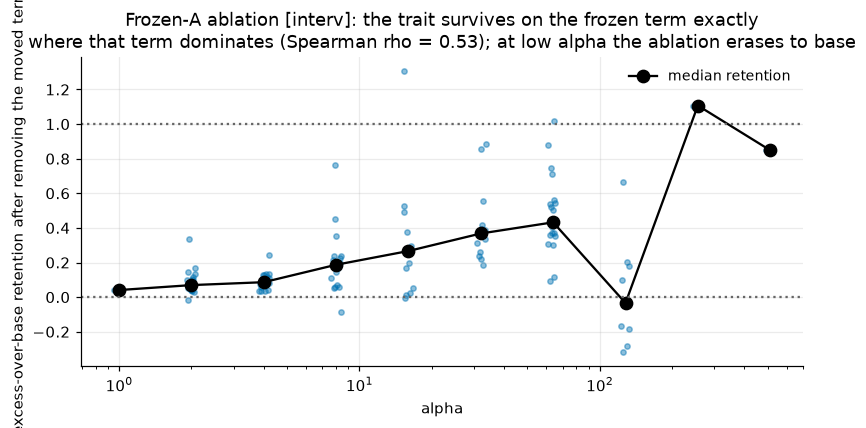

113 alive cells with usable excess (orig excess >= 0.005); retention median by alpha:
{1: 0.041, 2: 0.069, 4: 0.086, 8: 0.187, 16: 0.267, 32: 0.368, 64: 0.432, 128: -0.034, 256: 1.107, 512: 0.849}


In [11]:
# Frozen-A ablation, full ep20 grid: retention of trait when the moved term is removed
# (splice A -> A_init at exact per-module norms), vs alpha. Metric = EXCESS-over-base
# retention (never raw p ratio: ablation moves p toward base, not 0).
ab = json.loads((AN / "frozen_a_ablation_ep20_full.json").read_text())["results"]
ab = pd.DataFrame(ab)
tp = ab.student_tag.str.extract(r"ep20_lr(?P<lr>[0-9.e-]+)_r(?P<r>\d+)a(?P<a>\d+)")
ab["lr"], ab["rank"], ab["alpha"] = tp.lr.astype(float), tp.r.astype(int), tp.a.astype(int)
alive_ab = ab[ab.p_target_orig > 0.01].copy()
alive_ab["retention"] = ((alive_ab.p_target_ablated - BASE_PRIOR)
                         / (alive_ab.p_target_orig - BASE_PRIOR))
alive_ab.loc[(alive_ab.p_target_orig - BASE_PRIOR) < 0.005, "retention"] = np.nan  # excess floor
fig, ax = plt.subplots(figsize=(7.5, 4))
med = alive_ab.groupby("alpha").retention.median().dropna()
for a, sub in alive_ab.groupby("alpha"):
    ax.scatter(np.full(len(sub), a) * np.exp(np.random.RandomState(int(a)).uniform(-.05, .05, len(sub))),
               sub.retention, s=12, alpha=0.45, color="#0072B2")
ax.plot(med.index, med.values, "k-o", ms=8, label="median retention")
ax.axhline(0, color="0.4", ls=":"); ax.axhline(1, color="0.4", ls=":")
ax.set_xscale("log"); ax.set_xlabel("alpha")
ax.set_ylabel("excess-over-base retention after removing the moved term")
rho = stats.spearmanr(alive_ab.dropna(subset=["retention"]).alpha,
                      alive_ab.dropna(subset=["retention"]).retention)
ax.set_title("Frozen-A ablation [interv]: the trait survives on the frozen term exactly\n"
             f"where that term dominates (Spearman rho = {rho.statistic:.2f}); at low alpha the "
             "ablation erases to base")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()
print(f"{alive_ab.retention.notna().sum()} alive cells with usable excess "
      f"(orig excess >= 0.005); retention median by alpha:\n{med.round(3).to_dict()}")
# Row unit: one alive ep20 cell of the focus ds1 grid, ftseed1 (adaptive-era support).

## §4.4 What death is: loss of selectivity **[cal]**

The trait is trained through a numbers channel; the model's behavior everywhere else
should be untouched. Measure both sides on the strip runs: movement on the numbers
channel (training-like inputs) and displacement on neutral text (Pile logit KL vs
the base model).

strip activations, n=464 runs: AUC(pile KL) = 0.999, AUC(numbers-channel final drift) = 0.355
pile KL medians: alive 0.34 vs dead 15.40 nats


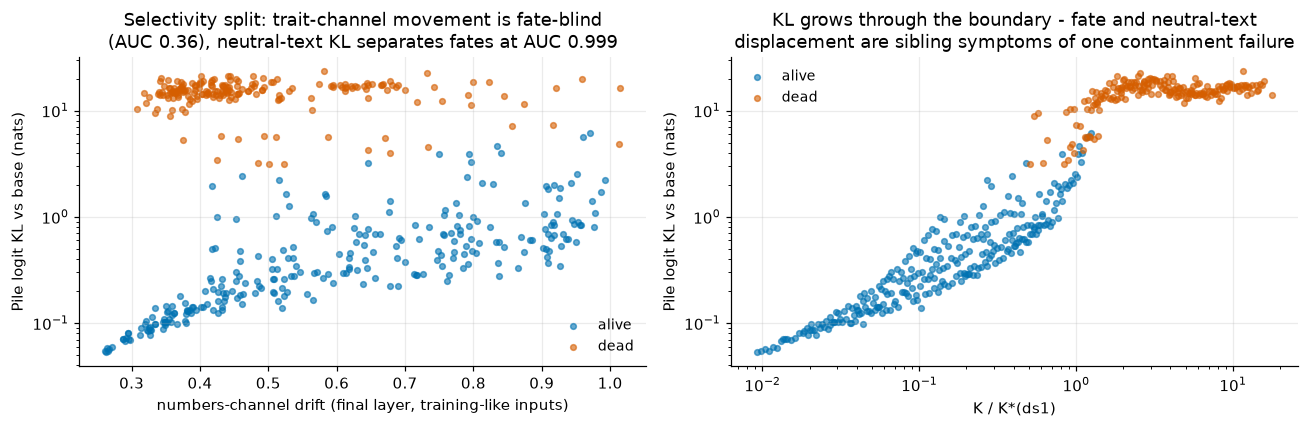

In [12]:
# Strip activations: layer-0 row of `drift` carries the logit-index KL; take final-layer
# rel_drift as the drift readout. ftseed1 cells only (the probe's design).
def load_act(cond):
    rows = []
    for r in (1, 2, 4, 8, 16, 32, 64, 128):
        p = AN / f"adapter_activations_strip_{cond}_r{r}.json"
        if not p.exists():
            continue
        d = json.loads(p.read_text())
        dr = pd.DataFrame(d["drift"])
        kl = dr[dr.layer == 0].set_index(["student_tag", "ftseed"]).kl_base_adapted
        fin = (dr[dr.layer == dr.layer.max()]
               .set_index(["student_tag", "ftseed"]).rel_drift)
        rows.append(pd.DataFrame({"kl": kl, "final_drift": fin}).reset_index())
    return pd.concat(rows, ignore_index=True)
pile = load_act("pile").rename(columns={"kl": "pile_kl", "final_drift": "pile_drift"})
nums = load_act("numbers").rename(columns={"kl": "num_kl", "final_drift": "num_drift"})
act = pile.merge(nums, on=["student_tag", "ftseed"], how="inner")
act = act.merge(strip[["tag", "seed", "test_p", "dead", "diverged", "K_rel"]],
                left_on=["student_tag", "ftseed"], right_on=["tag", "seed"], how="inner")
act = act[act.test_p.notna() & ~act.diverged.astype(bool)]
auc_pile = roc_auc_score(act.dead, act.pile_kl)
auc_num = roc_auc_score(act.dead, act.num_drift)
print(f"strip activations, n={len(act)} runs: AUC(pile KL) = {auc_pile:.3f}, "
      f"AUC(numbers-channel final drift) = {auc_num:.3f}")
print(f"pile KL medians: alive {act[~act.dead].pile_kl.median():.2f} vs "
      f"dead {act[act.dead].pile_kl.median():.2f} nats")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharey=False)
ax = axes[0]
for fate, color, lab in [(False, C_ALIVE, "alive"), (True, C_DEAD, "dead")]:
    sub = act[act.dead == fate]
    ax.scatter(sub.num_drift, sub.pile_kl.clip(1e-3), s=14, alpha=0.6, color=color, label=lab)
ax.set_yscale("log")
ax.set_xlabel("numbers-channel drift (final layer, training-like inputs)")
ax.set_ylabel("Pile logit KL vs base (nats)")
ax.set_title(f"Selectivity split: trait-channel movement is fate-blind\n(AUC {auc_num:.2f}), "
             f"neutral-text KL separates fates at AUC {auc_pile:.3f}")
ax.legend(fontsize=9)
ax = axes[1]
bins = np.geomspace(act.K_rel.min(), act.K_rel.max(), 16)
for fate, color, lab in [(False, C_ALIVE, "alive"), (True, C_DEAD, "dead")]:
    sub = act[act.dead == fate]
    ax.scatter(sub.K_rel, sub.pile_kl.clip(1e-3), s=14, alpha=0.6, color=color, label=lab)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("K / K*(ds1)"); ax.set_ylabel("Pile logit KL vs base (nats)")
ax.set_title("KL grows through the boundary - fate and neutral-text\ndisplacement are "
             "sibling symptoms of one containment failure")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()
# Row unit: one strip run with both activation probes (ftseed 1 by probe design).

**Reading.** Alive runs move the numbers channel just as much as dead runs (that
movement *is* learning). What separates fates is off-channel displacement: dead runs
have stopped confining their function change to the trained channel. "Collapse of
transfer" and "generic behavioral destruction" are one event — which is also why the
DEAD label could be defined on p_target alone.

## §4.5 When the decision happens **[adaptive]** **[recorded]**

Checkpointed runs (Test 2) and epoch contrasts put the fate decision *early*:

- ‖B(t)‖ grows as √(cumulative lr) on aggressive cells — a random-walk/diffusive
  signature, not ballistic accumulation; the endpoint-vs-lr exponent q falls from
  ~1.48 (ep5) to ~1.16 (ep20): a **ballistic→diffusive crossover**, decisions made
  while growth is still ballistic.
- **K\* barely moves with dose accumulation**: 4× the steps shifts the boundary only
  ~1.3× (K\* ∝ epochs^−0.2) — a cumulative-update story predicts ∝ 1/epochs, many σ
  away. The endpoint dose threshold grows sublinearly (~√T bracket).
- The one captured *dying* seed was indistinguishable from surviving siblings in
  every norm/coherence trace at every checkpoint — whatever separates it is not in
  the size trajectory. (This is what pushed the program toward direction/subspace.)
- Loss curves are unavailable (the student trainer kept no trainer state); the
  endpoint substitute (§1.2's postmortem CE) rules out optimization failure.

Open: a checkpoint-level fate eval + rescue-branching experiment (stop at t, rescale,
continue) would turn "decision is early" from inference into observation.

## §4.6 Direction: a cautionary tale, and what survives

The direction program is the best example in this repo of a signal that *looked*
mechanistic and was killed properly:

1. cos(ΔW, W₀) carried fate information beyond size (`[adaptive]`: matched-dose AUC
   0.79; dying seeds more anti-aligned in 13/17 mixed cells, p = 0.025) — the
   program's first seed-level signal.
2. The **surgery** `[interv]`: flip/strip/10×-amplify the W₀-aligned sliver at exact
   matched norms — max |Δp| 0.007, 1/34 fate flips. **Causally inert.**
3. The **strip** `[cal]`: the sign-fate association does not replicate on calibrated
   support (29% dead vs 28% alive, against the adaptive-era 63%/25%).

Verdict: cos(ΔW, W₀) is fully retired — per the current `nors_asks` §1.2b wording,
"not a mechanism, and not even a robust marker"; seed-level results built on it are
flagged for re-examination as population artifacts (`seed_fate_direction.ipynb`
predates the strip and has NOT been updated — treat its ds1 headline as stale). What survives of "direction does work": the λ experiment's
history-dependence (§4.7) — trained-dead updates are worse *per unit norm* — and the
spread surgery's residual (which directions, not how spread out). The open axis is
**subspace identity**: energy in W₀'s top singular subspaces / activation-space
placement, not any summary statistic yet tried.

## §4.7 The causal rungs **[interv]**

Everything above is observational or identity-level. The eval-time interventions are
the program's first causal sentences: take a *trained* adapter, modify the update
itself (scale, direction-component, or spectrum), re-evaluate.

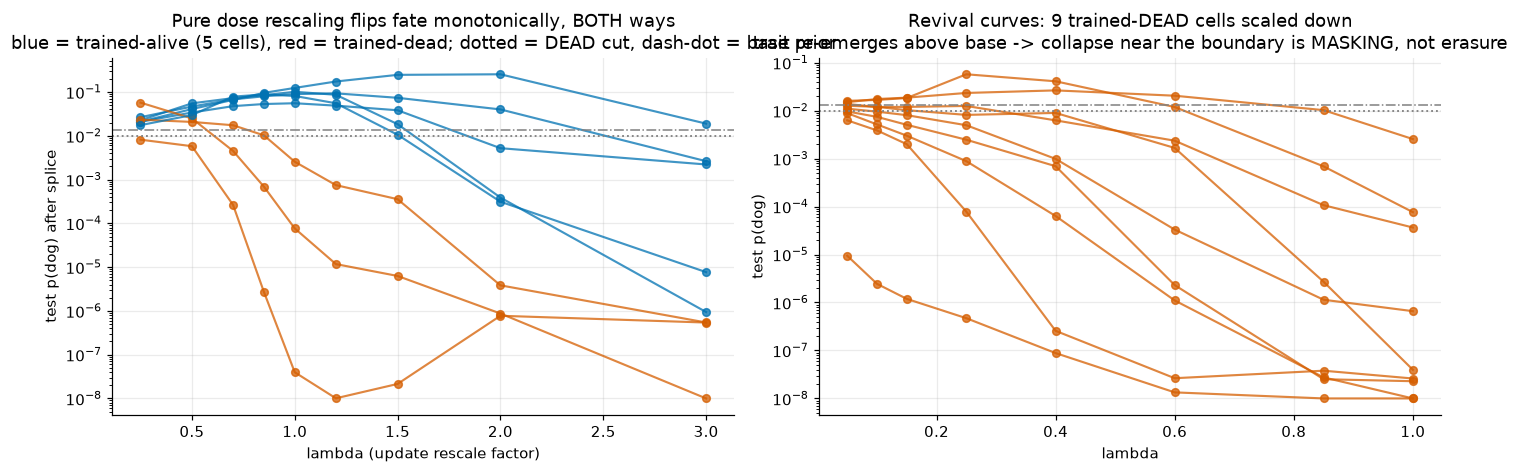

effective dose lam * K/K* at the fate flip (history-dependence):
              count    min    50%    max
trained_dead                            
False           4.0  0.890  1.647  2.059
True            5.0  0.075  0.352  1.037
-> trained-ALIVE updates keep the trait up to lam-doses ~1.65x K* (median), while trained-DEAD updates revive only below ~0.35x K* (median):
   dose is causally sufficient for fate, but each update's threshold depends on the
   direction it learned - 'direction quality' is real, just not cos(dW, W0).
   (In measured-dw units the recorded gap is ~2x: die at lam*dw 0.14-0.21 vs revive
   below 0.08-0.13, nors_asks 5.5 - the K-unit gap here is wider because trained-dead
   cells sit deeper past the boundary before rescaling.)


In [13]:
# Lambda dose-response: dW -> lam*dW (direction preserved) on 8 boundary-straddling cells.
lam_files = sorted(AN.glob("frozen_a_ablation_scale_lam*.json"))
lam_rows = []
for f in lam_files:
    d = json.loads(f.read_text())
    for r in d["results"]:
        lam_rows.append(dict(tag=r["student_tag"], ftseed=r["ftseed"],
                             lam=r["scale_lambda"], p=r["p_target_ablated"],
                             kl=r["pile_kl_base_ablated"], p_orig=r["p_target_stored"]))
lam = pd.DataFrame(lam_rows).sort_values("lam")
lam["cell"] = lam.tag + "/s" + lam.ftseed.astype(str)
lam["trained_dead"] = lam.p_orig < 0.01

# Revival curves (9 trained-dead cells, lam <= 1).
rev_rows = []
for f in sorted(AN.glob("frozen_a_ablation_revival_lam*.json")):
    d = json.loads(f.read_text())
    for r in d["results"]:
        rev_rows.append(dict(tag=r["student_tag"], ftseed=r["ftseed"],
                             lam=r["scale_lambda"], p=r["p_target_ablated"]))
rev = pd.DataFrame(rev_rows).sort_values("lam")
rev["cell"] = rev.tag + "/s" + rev.ftseed.astype(str)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
for cell, sub in lam.groupby("cell"):
    color = C_DEAD if sub.trained_dead.iloc[0] else C_ALIVE
    ax.plot(sub.lam, sub.p.clip(1e-8), "o-", color=color, alpha=0.75, ms=5, lw=1.4)
ax.axhline(0.01, color="0.5", ls=":", lw=1.2)
ax.axhline(BASE_PRIOR, color="0.5", ls="-.", lw=1.0)
ax.set_yscale("log"); ax.set_xlabel("lambda (update rescale factor)")
ax.set_ylabel("test p(dog) after splice")
ax.set_title("Pure dose rescaling flips fate monotonically, BOTH ways\n"
             f"blue = trained-alive ({int((~lam.trained_dead).sum()/lam.lam.nunique())} cells), "
             f"red = trained-dead; dotted = DEAD cut, dash-dot = base prior")
ax = axes[1]
for cell, sub in rev.groupby("cell"):
    ax.plot(sub.lam, sub.p.clip(1e-8), "o-", color=C_DEAD, alpha=0.75, ms=5, lw=1.4)
ax.axhline(0.01, color="0.5", ls=":", lw=1.2); ax.axhline(BASE_PRIOR, color="0.5", ls="-.", lw=1.0)
ax.set_yscale("log"); ax.set_xlabel("lambda"); ax.set_ylabel("test p(dog)")
ax.set_title(f"Revival curves: {rev.cell.nunique()} trained-DEAD cells scaled down\n"
             "trait re-emerges above base -> collapse near the boundary is MASKING, not erasure")
fig.tight_layout(); plt.show()

# History-dependent crossing: effective dose lam * K/K* at the fate flip, by training
# fate. (K_rel is computed from each cell's own tag - the intervention cells are
# adaptive-era boundary cells, so the strip's measured dw is not available for them;
# K is the dose scale the level-set result licenses.)
def k_rel_of_tag(tag):
    m = re.fullmatch(r"ep\d+_lr([0-9.e-]+)_r(\d+)a(\d+)", tag)
    lr, r, a = float(m[1]), int(m[2]), int(m[3])
    return lr * a ** B_DESIGN * r ** C_DESIGN / KSTAR_DS1
def crossing(sub, dead_at_train):
    sub = sub.sort_values("lam")
    alivemask = sub.p >= 0.01
    d0 = k_rel_of_tag(sub.tag.iloc[0])
    if dead_at_train:   # revive threshold: largest lam still alive
        lams = sub.lam[alivemask]
        return d0 * lams.max() if len(lams) else np.nan
    lams = sub.lam[~alivemask]   # kill threshold: smallest lam already dead
    return d0 * lams.min() if len(lams) else np.nan
cross = []
for cell, sub in pd.concat([lam, rev.assign(trained_dead=True, p_orig=np.nan)]).groupby("cell"):
    td = bool(sub.trained_dead.iloc[0])
    cross.append(dict(cell=cell, trained_dead=td, flip_dose=crossing(sub, td)))
cross = pd.DataFrame(cross).dropna()
print("effective dose lam * K/K* at the fate flip (history-dependence):")
print(cross.groupby("trained_dead").flip_dose.describe().round(3)[["count", "min", "50%", "max"]])
med_a = cross.loc[~cross.trained_dead, "flip_dose"].median()
med_d = cross.loc[cross.trained_dead, "flip_dose"].median()
print(f"-> trained-ALIVE updates keep the trait up to lam-doses ~{med_a:.2f}x K* (median), "
      f"while trained-DEAD updates revive only below ~{med_d:.2f}x K* (median):")
print("   dose is causally sufficient for fate, but each update's threshold depends on the")
print("   direction it learned - 'direction quality' is real, just not cos(dW, W0).")
print("   (In measured-dw units the recorded gap is ~2x: die at lam*dw 0.14-0.21 vs revive")
print("   below 0.08-0.13, nors_asks 5.5 - the K-unit gap here is wider because trained-dead")
print("   cells sit deeper past the boundary before rescaling.)")

Spread surgery [interv]: Pile KL vs base (nats) per cell x variant, at exactly matched Frobenius energy. top1 = all energy concentrated on the top direction (RAISES the spectral norm by sqrt(srank)); flat = spectrum equalized. Row = one trained adapter.


,,variant,flat,orig,top1
tag,seed,fate,,,
ep20_lr1e-4_r4a32,1,alive,1.349,1.511,1.375
ep20_lr1e-4_r64a128,1,dead,3.365,11.832,4.046
ep20_lr1e-5_r64a512,1,alive,0.494,1.064,1.500
ep20_lr2e-4_r64a8,1,alive,0.510,0.714,0.476
ep20_lr3e-4_r8a8,1,alive,3.755,2.774,2.062
ep20_lr4e-4_r32a8,1,dead,5.726,5.787,3.642
ep20_lr4e-4_r64a8,1,dead,4.862,5.918,3.252
ep20_lr8e-4_r8a1,1,alive,5.314,2.110,1.461


top1 vs orig: damage reduced in 7/8 cells (median -0.68 nats) despite the LARGER peak ->
the peak account is refuted twice over: bigger peak + same energy = LESS damage.
flat is non-monotone in rank (kills the r8a1 trait, but reduces damage at r64):
summary spread is not the beyond-dose axis either (matched-pair check rejected it).


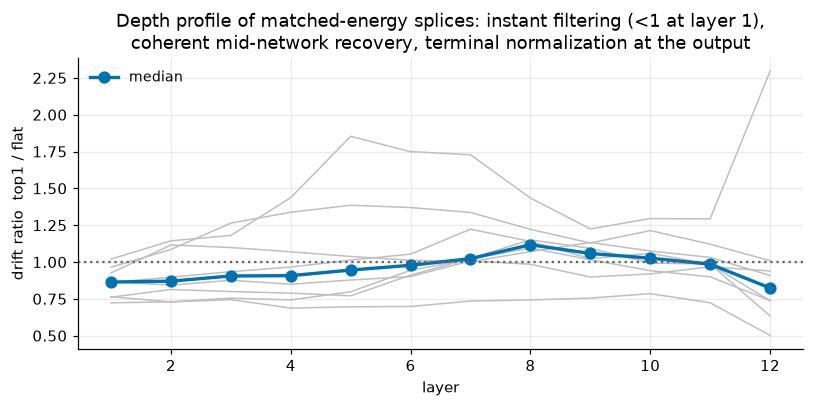

In [14]:
# Spread surgery: top1 (all energy in the top direction) vs flat (equalized spectrum)
# at matched ||dW||_F, 8 cells. Plus the depth profile of the same splices.
ss_rows = []
for f in sorted(AN.glob("spread_surgery_*.json")):
    d = json.loads(f.read_text())
    for r in d["results"]:
        ss_rows.append(dict(tag=r["student_tag"], seed=r["ftseed"], fate=r["fate"],
                            variant=r["variant"], p=r["p_target"], kl=r["pile_kl_base"]))
ss = pd.DataFrame(ss_rows)
piv = ss.pivot_table(index=["tag", "seed", "fate"], columns="variant",
                     values=["kl", "p"]).round(4)
print(
    "Spread surgery [interv]: Pile KL vs base (nats) per cell x variant, at exactly matched "
    "Frobenius energy. top1 = all energy concentrated on the top direction (RAISES the "
    "spectral norm by sqrt(srank)); flat = spectrum equalized. Row = one trained adapter.")
display(compare_table(piv["kl"]))
kl_delta = (piv["kl"]["top1"] - piv["kl"]["orig"])
print(f"top1 vs orig: damage reduced in {(kl_delta < 0).sum()}/{len(kl_delta)} cells "
      f"(median {kl_delta.median():+.2f} nats) despite the LARGER peak ->")
print("the peak account is refuted twice over: bigger peak + same energy = LESS damage.")
print("flat is non-monotone in rank (kills the r8a1 trait, but reduces damage at r64):")
print("summary spread is not the beyond-dose axis either (matched-pair check rejected it).")

# Depth profile of the same splices.
dp = json.loads((AN / "spread_depth_probe.json").read_text())["results"]
dp = pd.DataFrame(dp)
if {"variant", "layer"}.issubset(dp.columns):
    drift_col = [c for c in ("rel_drift", "drift") if c in dp.columns][0]
    ratio = (dp.pivot_table(index=["student_tag", "layer"], columns="variant", values=drift_col)
               .eval("top1 / flat").rename("ratio").reset_index())
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    for tag, sub in ratio.groupby("student_tag"):
        ax.plot(sub.layer, sub.ratio, color="0.75", lw=1)
    medr = ratio.groupby("layer").ratio.median()
    ax.plot(medr.index, medr.values, "o-", color="#0072B2", lw=2.2, ms=7, label="median")
    ax.axhline(1, color="0.4", ls=":")
    ax.set_xlabel("layer"); ax.set_ylabel("drift ratio  top1 / flat")
    ax.set_title("Depth profile of matched-energy splices: instant filtering (<1 at layer 1),\n"
                 "coherent mid-network recovery, terminal normalization at the output")
    ax.legend(fontsize=9)
    fig.tight_layout(); plt.show()
else:
    print("depth probe JSON schema differs; recorded result: median top1/flat drift ratio "
          "0.86 (layer 1) -> 1.12 (layer 8) -> 0.82 (output); final ratio < 1 in 6/8 cells.")
# Row unit: one trained adapter (table); one (adapter, layer) (chart).

**The mechanism picture after the interventions.** The network *filters a peaked
injection immediately* (within the first block), partially recovers it through
coherent same-direction accumulation, and absorbs it again at the output — which is
*why* total energy beats the peak as the damage variable: a concentrated update is
locally louder but propagates less. Together: **dose (Frobenius energy) is the
causal size variable; the residual, history-dependent factor is which subspace the
energy occupies** — with summary statistics of the spectrum (spread, srank, module
concentration) and the W₀-projection all ruled out as that factor.

Not yet causal: everything at *training* time. The λ results are eval-time splices;
whether clamping dose during training prevents death, and whether re-training B in a
fixed subspace reproduces fate, are the open clamp/retrain tiers of
`causal_plan.md`.

## §4.8 The main argument, audited — where the holes are

The working hypothesis, stated as a four-step chain:

> **(A1)** A collapse phenomenon exists and is empirically governed by student HPs.
> **(A2)** The *size* of the LoRA update directly **causes** collapse — shown
> correlationally and causally. **(A3)** The student HPs set that size.
> **(A4)** Frobenius is the size that matters.

Step-by-step audit of what is proven and what a sharp reviewer will hit:

**A1 — proven, at the strongest standard in the program.** Bimodal fate (§1.1), the
law replicated across arms/inits/animals (§2.2–2.4), and the whole thing
re-established on outcome-independent placement (§2.5, `[cal]`). The strip
specifically dispels the support/adaptive confounds that hung over the earlier
grids. No hole here beyond the scope table in §2.6 (width, pool, ep20, wd=0).

**A3 — proven.** Dose law R² = 0.97 with both curvatures `[cal]` (§4.2), each
exponent traced to the update's exact two-term anatomy `[ident]` (§4.3), and the
collapse law recovered as the dose law's level set — the H segment exactly
(|z| = 0.0). *Minor hole:* the L segment closes at |z| = 0.5 only boundary-locally,
and the residual tension names an untested assumption (θ constant in α) —
measurable on existing strip data. Close it before writing "derived" anywhere.

**A4 — proven within its scope, with two honest asterisks.** The pre-registered
threshold test, the γ_S sign, and the interventional spread surgery all point the
same way (§4.1, §4.7). Asterisk 1: θ_F is the *flattest* threshold, not flat — its
own drift excludes zero, and the c-exponent story absorbs it; say "Frobenius
behaves lawfully; spectral does not", not "the Frobenius threshold is invariant".
Asterisk 2: **single width.** Nor's Adam-width argument means the Frobenius-vs-
spectral verdict could in principle be a 768-width artifact; one more model size
kills this permanently and nothing else does.

**A2 — the load-bearing step, and where the real holes are.** What is established:
P(death) is a soft threshold on measured dw at AUC 0.998 `[cal]` (correlational
leg ✔), and pure λ-rescaling of the trained update flips fate monotonically in
*both* directions, including revival of dead models `[interv]` (causal leg ✔ — at
evaluation time). Three holes, in decreasing severity:

1. **The causal leg is eval-time, not train-time.** The λ experiment licenses "the
   *endpoint update's* magnitude causally controls the behavioral outcome." It does
   not yet license "large per-step updates during training cause the collapse
   outcome" — training could, in principle, produce death through a path whose
   endpoint *also* scales with dose. The clamp tier (cap dose during training →
   prediction: no death above K\*) is the missing experiment and `causal_plan.md`
   already specifies it. Until then, the claim should be worded as *endpoint-dose
   sufficiency*, which is what was shown.
2. **Size is causally sufficient but not the complete cause.** The λ flip dose is
   history-dependent — trained-alive updates tolerate ~2× the dose trained-dead
   updates revive at — so a direction/subspace factor of about 2 modulates the
   threshold, and it is currently unnamed (spread, srank, module concentration and
   the W₀-projection are all ruled out). Relatedly, *within* a mixed cell, endpoint
   size does not pick which seed dies (size diagnostics at coin-flip within cells;
   the old within-cell direction signal is retired with cos). Honest form: **dose
   sets the death probability between cells and is sufficient to flip fate; a
   bounded (~2×) direction-quality factor sets each update's personal threshold.**
   A reviewer who hears "size directly causes collapse" will ask exactly this; the
   answer is already in hand if it is worded this way.
3. **Why crossing kills is still open.** The selectivity result (§4.4) shows what
   death *is* (containment failure — fate and Pile-KL as sibling symptoms), and the
   depth probe shows how the network processes the injection, but there is no
   mechanistic account yet of why exceeding θ destroys the behavioral prior rather
   than just adding noise. This is a "mechanism of the mechanism" hole — fine to
   leave open in a paper, but it should be framed as open, not implied solved.

**Net assessment: the chain A1→A3→A4 is essentially closed at calibrated strength
on this model; A2's correlational leg is closed; A2's causal leg is closed at
eval time with the training-time clamp as the one missing experiment, and the
"directly causes" wording needs the two-sentence qualification above.** The
cheapest path to "no major holes": (i) run the clamp tier, (ii) run one more
width, (iii) fit θ(α) on the strip, (iv) keep the direction factor as an explicitly
bounded open term rather than a defect.

---
# Part V — Evidence audit and demonstration blueprint (Q3)

## §5.1 The claim ledger

Every load-bearing claim, its strongest current evidence class, and its status.
"Replicated" means at least two independent designs agree.

In [15]:
ledger = pd.DataFrame([
    # claim, class, status, where
    ("Collapse is a bimodal per-run fate with an empty trough", "cal", "replicated everywhere", "Part I; every campaign"),
    ("Dead runs still fit their training data (not optimization failure)", "adaptive", "established", "collapse_law_generality 12"),
    ("Collapse is not trait-specific (trait-free null collapses too)", "adaptive", "established, 22-cell control", "collapse_mechanism 6c"),
    ("Boundary K = lr.alpha^b.r^c >= K*, b~0.56 (L), c~-0.09", "cal", "replicated x3 designs", "Part II; nors_asks 7"),
    ("Exponents generalize across 3 teachers x 2 inits (I2~0)", "adaptive", "replicated", "2.2 (recomputed)"),
    ("Rank protective - model-free at matched (lr, alpha)", "adaptive", "replicated, zero reversals", "2.3 (recomputed)"),
    ("K* transfers cross-init at 1.02x (krungs both arms)", "adaptive", "replicated, executed", "top20_krungs 5+9; 2.4"),
    ("K* transfers cross-ANIMAL (cat/lion/pig on dog's anchor)", "adaptive", "replicated, arms still draining", "2.4 (recomputed)"),
    ("Per-teacher K* spread 0.85-1.14x (krungs); 66%-of-variance claim", "adaptive", "spread executed; 66% is notes-only (14 lost in wipe)", "top20_krungs 5; 2.4"),
    ("Law is REGIONAL: b_L 0.499+/-0.064, b_H 0.882+/-0.098", "cal", "established 3.3-sigma", "2.5 (recomputed)"),
    ("Second boundary: optimization divergence at K/K* >~ 12", "cal", "established", "2.5 (recomputed)"),
    ("DEAD threshold is arm-specific (live-mode/10 rule)", "adaptive", "established; a convention", "1.1 (recomputed)"),
    ("Survivor transfer is HUMPED, peak K/K* ~ 0.3-0.6", "cal + interv", "replicated x3 + causal in-run", "2.5, 4.7"),
    ("Yield (transfer level) does NOT generalize (11x spread)", "adaptive", "established", "Part III"),
    ("Rank buys survivor transfer at matched K (twins 1.25-1.43x)", "adaptive", "executed (krungs); +0.124/I2=0 refit is notes-only (15 lost)", "top20_krungs 7+9.5"),
    ("Fate is a soft threshold on dose, AUC ~0.99", "cal", "replicated (adaptive 0.99 too)", "4.1 (recomputed)"),
    ("Frobenius, not spectral, is the lawful norm", "cal + interv", "settled (single-width caveat)", "4.1, 4.7"),
    ("Dose law lr^1.05 alpha^0.69 r^-0.24, R2~0.97, both quadratics real", "cal", "established", "4.2 (recomputed)"),
    ("Collapse law = level set of dose law (H closure |z|=0.0)", "cal", "established boundary-locally", "4.2; nors_asks 7.4"),
    ("Two-term anatomy: frozen straight, moved convex, alpha crossover", "ident + cal", "established", "4.3 (recomputed)"),
    ("Trait rides the dominant term (double dissociation)", "interv", "established", "4.3; nors_asks 5.4"),
    ("Death = loss of selectivity (pile KL AUC 0.999; alive 0.33 vs dead 15.4 nats)", "cal", "established", "4.4 (recomputed)"),
    ("Fate decision is EARLY (q crossover; K* ~ epochs^-0.2)", "adaptive", "established, indirect", "4.5 [recorded]"),
    ("Dose causally flips fate at eval time, both directions", "interv", "established", "4.7 (recomputed)"),
    ("Near-boundary death is MASKING (dead models revivable)", "interv", "established", "4.7 (recomputed)"),
    ("Flip dose is history-dependent (direction quality real)", "interv", "established", "4.7 (recomputed)"),
    ("cos(dW, W0) as fate mechanism", "interv + cal", "RETIRED (marker only)", "4.6"),
    ("Summary spread / peak as the damage variable", "interv", "REFUTED", "4.7"),
    ("Which subspace property sets the personal threshold", "-", "OPEN", "causal_plan"),
    ("Training-time causation (clamp / retrain tiers)", "-", "OPEN, designed", "causal_plan"),
    ("Pretraining maturity gates transfer BOTH sides (ckpt line)", "adaptive", "new 08-10, arms draining", "checkpoint_distillation_analysis"),
    ("Width/model-size robustness (Adam-width objection)", "-", "OPEN - biggest gap", "nors_asks 1"),
], columns=["claim", "class", "status", "where"])
with pd.option_context("display.max_colwidth", 90):
    display(ledger.style.set_properties(**{"text-align": "left"})
            .apply(lambda s: ["color: #B00020" if ("RETIRED" in v or "REFUTED" in v)
                              else ("color: #806000" if "OPEN" in v else "")
                              for v in s], subset=["status"], axis=0)
            .hide(axis="index"))

claim,class,status,where
Collapse is a bimodal per-run fate with an empty trough,cal,replicated everywhere,Part I; every campaign
Dead runs still fit their training data (not optimization failure),adaptive,established,collapse_law_generality 12
Collapse is not trait-specific (trait-free null collapses too),adaptive,"established, 22-cell control",collapse_mechanism 6c
"Boundary K = lr.alpha^b.r^c >= K*, b~0.56 (L), c~-0.09",cal,replicated x3 designs,Part II; nors_asks 7
Exponents generalize across 3 teachers x 2 inits (I2~0),adaptive,replicated,2.2 (recomputed)
"Rank protective - model-free at matched (lr, alpha)",adaptive,"replicated, zero reversals",2.3 (recomputed)
K* transfers cross-init at 1.02x (krungs both arms),adaptive,"replicated, executed",top20_krungs 5+9; 2.4
K* transfers cross-ANIMAL (cat/lion/pig on dog's anchor),adaptive,"replicated, arms still draining",2.4 (recomputed)
Per-teacher K* spread 0.85-1.14x (krungs); 66%-of-variance claim,adaptive,spread executed; 66% is notes-only (14 lost in wipe),top20_krungs 5; 2.4
"Law is REGIONAL: b_L 0.499+/-0.064, b_H 0.882+/-0.098",cal,established 3.3-sigma,2.5 (recomputed)


## §5.2 What separated real evidence from artifact

The program produced four confident wrong results and caught all of them. The
catching mechanisms are the actual methodology lesson — each is now a standing rule:

1. **The DEAD-threshold trap** (§1.1). A cut tuned on one arm produced I² = 75–78%
   exponent "heterogeneity" (p < 0.001!) that vanished at the right cut. → *Every
   inherited analysis constant must be revalidated on new data; thresholds come from
   each arm's own histogram.*
2. **The support/leverage trap** (§2.1). "Rank is not in the law" was an artifact of
   a grid that never ran rank < 4; no estimator can rescue an axis the design never
   varied. → *Check design coverage before spending seeds.* Its mirror: the lone
   (ln α)² probe was unidentifiable on the adaptive grid's correlated support —
   the strip settled it (+0.018 ± 0.007, p = 8e-3) in the *opposite* direction of
   the adaptive-era retraction. (Its sibling: within-rank fate AUCs saturate ≥ 0.99
   for both norms on the strip and are *retired as evidence* — a discriminator can
   be too easy as well as confounded.)
3. **The composition trap.** Per-arm ‖ΔW‖ fate gaps read *reversed* on one arm
   because arms carried unequal HP/budget mixes (Table 1.1b); the ws1 seed-level
   cos signal died exactly at cell fixed-effects. → *Never read cross-arm contrasts
   off unequal coverage; always push seed-level claims through within-cell tests.*
4. **The adaptive-inference trap** (§2.5). Four "beautiful" adaptive-era statistics
   (an lr regime shift among them) dissolved on the calibrated strip, while the real
   effects (α², regional b) sharpened. → *Adaptive data is for discovery and
   replication-of-direction; calibrated designs are for inference. The strip's 852
   GPU-jobs bought the right to say "p = 4e-3" and mean it.*

Also retired on identification grounds: fixed-(lr, α) rank ladders (K and rank
perfectly collinear — circular as a c estimate), per-arm K\* placement for new
campaigns (tunes the small variance term while breaking cell pairing), and the
"α/r scale" framing (loses to absolute α by 21/105 cells).

## §5.3 The demonstration blueprint

What a paper-strength case looks like, given the ledger — ordered by how much each
item de-risks the story:

1. **A second width/model size** (pythia-410m or 1b, one strip-style factorial +
   one law refit). Settles Nor's Adam-width objection, the only structural threat to
   the Frobenius framing; also tests whether K\* scales as any μP-style prediction.
   Without this, every norm-based claim carries a permanent asterisk.
2. **Training-time causation** — the clamp tier (project each step's update to cap
   dose; prediction: no death above K\* while clamped) and the retrain-B tier
   (re-train with A frozen at a dead run's subspace; prediction: fate follows
   subspace). Converts the mechanism from "eval-time causal" to causal simpliciter.
   Designs already exist in `causal_plan.md`.
3. **A second pool/dataset family** (constrained-generation pools already exist at
   ≥10k-usable coverage): one law refit. Cheap, closes the "one pool" scope line.
4. **Subspace identity** — the open mechanism axis: ΔW energy resolved against W₀'s
   singular subspaces and against activation covariance, then a *targeted* surgery
   (move energy between identified subspaces at matched norm) rather than another
   summary statistic. This is what would name the "direction quality" the λ
   experiment proved exists.
5. **An SGD (or wd > 0) arm**: the weak-form mechanism predicts b → ~1.5 under SGD —
   a sharp, cheap, falsifiable prediction that would powerfully confirm the
   optimizer-mediated dose story (or break it usefully).
6. **Checkpoint fate + rescue branching**: turns "the decision is early" into a
   directly observed decision time.
7. **Provenance repair (cheap, disk-only):** re-derive the two wipe-lost analyses —
   the per-arm K\*₅₀ refit (old §14) and the conditional-transfer refit + its
   `fit_conditional_transfer` estimator (old §15) — so the "teachers 66% of K\*
   variance", rank-4 dip, and rank-conditional claims stop resting on session notes.
   Likewise keep `transfer_factor_decomposition.ipynb` re-running as the cat/lion/pig
   arms drain, and mark `seed_fate_direction.ipynb` stale in-file.

**The paper-grade figure set already in hand**: the six-arm forest (§2.2), the
cross-animal boundary chart (§2.4), the strip fate maps + regional law (§2.5), the
dose-AUC and level-set closure (§4.1–4.2), the selectivity split (§4.4), and the λ
dose-response/revival pair (§4.7). Each is recomputed in this notebook from primary
artifacts.

---
*Builder: `scripts/build_collapse_evidence_nb.py`. Keep builder and notebook in
sync. SSOTs for the underlying experiments: `nors_asks.ipynb` (norms, dose,
interventions, strip), `collapse_law_generality.ipynb` (six-arm law),
`collapse_mechanism.ipynb` (assumption ledger, temporal), `top20_krungs_ds1.ipynb`
(cross-init ladder), `collapse_campaigns_k_alpha_rank.ipynb` (threshold conventions;
the cross-animal band notebook was lost in the 08-05 wipe — §2.4 here recomputes it),
`transfer_factor_decomposition.ipynb` (transfer-level factors).*